# 06 — ALTA10 Research Synthesis, Validation and Next Steps

**Capstone research continuation | October 20, 2026 snapshot**

This file builds on `04_Visuals_and_Graphics_P1.ipynb` and
`05_Visuals_and_Graphics_P2.ipynb`, but reloads its own inputs. Run from top
to bottom, either as a Python script or using VS Code's `# %%` cells.

**Research question:** Can LiDAR, turbine SCADA, power-curve behavior, and
preliminary wake/terrain modeling help identify potentially biased or
malfunctioning turbine wind-speed instruments?

**Interpretation rule:** Differences between instruments are *diagnostic*,
not proof that any one sensor is incorrect. In particular, LiDAR measurement
geometry, SCADA channel provenance, directional references, and operating
state require sponsor confirmation.

The code includes:
1. Data and turbine specification checks
2. Reproducible 1-second LiDAR -> 10-minute TI and provisional k proxies
3. Six-turbine geographic / matched-conditions comparisons
4. LiDAR anomalous-low-speed diagnostics and sensitivity tests
5. LiDAR vs SCADA wind speed and direction validation
6. Six-turbine GE power-curve validation and error-by-wind-speed plots
7. Baseline Jensen / preliminary Gaussian-style wake overlays on the USGS DEM
8. Research findings, limitations, next tests, and sponsor questions

**Dependencies:** pandas, numpy, matplotlib, pyarrow, geopandas, rasterio.
The met-mast dataset is deliberately **not** used pending data review.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

# This file belongs in PROJECT_ROOT/notebooks/alex_notebooks/.
# Data remain in PROJECT_ROOT/data/ (not inside the notebooks folder).
# Locate the project from the script file or Jupyter working directory first.
# Keep the explicit Windows path as a fallback if Jupyter launches elsewhere.
FALLBACK_PROJECT_ROOT = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)


def find_project_root():
    starting_points = []
    if "__file__" in globals():  # Standard .py file / VS Code Python cells
        starting_points.append(Path(__file__).resolve().parent)
    starting_points.append(Path.cwd())  # Jupyter notebooks

    for start in starting_points:
        for folder in (start, *start.parents):
            if (folder / "data" / "processed").is_dir() and (folder / "data" / "raw").is_dir():
                return folder

    if (FALLBACK_PROJECT_ROOT / "data").is_dir():
        return FALLBACK_PROJECT_ROOT

    raise FileNotFoundError(
        "Could not locate CU-Capstone-Project/data. "
        "Place this file under notebooks/alex_notebooks, run from the project, "
        "or update FALLBACK_PROJECT_ROOT."
    )


PROJECT_ROOT = find_project_root()
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks" / "alex_notebooks"
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
LIDAR_DIR = DATA_DIR / "raw" / "lidar_data"
RESULT_DIR = PROCESSED_DIR / "06_research_synthesis"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

LIDAR_TURBINES = ["WTG159", "WTG170", "WTG171", "WTG173", "WTG180", "WTG184"]
WIND_FROM_DEG = 231.72       # purely illustrative wind-from sector; not verified site inflow
FREE_STREAM_SPEED = 8.2      # m/s; illustrative inflow
BASELINE_K = 0.05           # uncalibrated Jensen expansion coefficient
SAVE_FIGURES = True
SAVE_TABLES = True
RUN_TERRAIN_WAKE_MAPS = True
GRID_RESOLUTION_M = 10
GRID_PADDING_M = 1000
MIN_LIDAR_VALID_SECONDS = 540   # 90% completeness in a 10-minute interval
MIN_LIDAR_MEAN_MS = 3.0
# For a quick smoke-test use a small number (e.g., 3) before the full 134-day run.
MAX_FILES_PER_TURBINE = None

def find_input(filename):
    hits = sorted(DATA_DIR.rglob(filename))
    if not hits:
        raise FileNotFoundError(f"Missing '{filename}' under {DATA_DIR}")
    return hits[0]


def normal_id(value):
    """Convert both GE-159, WTG_T159 and WTG159 labels to WTG159."""
    import re
    match = re.search(r"(\d+)\s*$", str(value).strip())
    return "WTG" + match.group(1) if match else str(value).strip()


def to_utc_naive(series):
    """Provisional assumption: input timestamps are UTC, output is UTC-naive."""
    return pd.to_datetime(series, errors="coerce", utc=True).dt.tz_localize(None)


def circular_difference(a, b):
    return (a - b + 180.0) % 360.0 - 180.0


def circular_stats(differences):
    a = np.deg2rad(pd.to_numeric(differences, errors="coerce").dropna())
    if len(a) == 0:
        return (np.nan, np.nan)
    s, c = np.mean(np.sin(a)), np.mean(np.cos(a))
    return np.rad2deg(np.arctan2(s, c)), np.hypot(s, c)


def save_table(df, name):
    if SAVE_TABLES:
        df.to_csv(RESULT_DIR / f"{name}.csv", index=False)


def finish_plot(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(RESULT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()


print(f"Project root: {PROJECT_ROOT}")
print(f"Notebook location: {NOTEBOOK_DIR}")
print(f"Project data: {DATA_DIR}")
print(f"Derived outputs: {RESULT_DIR}")

Project root: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project
Notebook location: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\notebooks\alex_notebooks
Project data: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data
Derived outputs: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\06_research_synthesis


## 1. Findings already observed (historical snapshot; *not* re-computed here)

- **WTG159:** median SCADA minus LiDAR speed ~**+1.31 m/s** over 15,018
  matched 10-minute intervals. Original mean +1.71 m/s, RMSE 2.81 m/s.
  Removing selected anomalous intervals left a median ~+1.306 m/s.
- **Extreme events:** On June 8, 2026, **24,273/25,776 = 94.17%** of eligible
  paired seconds had Sensor 1 >20 m/s and LiDAR <8 m/s at WTG159, versus
  almost none at the other five LiDAR turbines. May 16–17 also showed abrupt
  LiDAR/Vlos changes while turbine-associated readings remained higher.
  The screen is an *anomaly flag*, not proof of a LiDAR failure.
- **Six-turbine median TI:** WTG159 10.01%, WTG170 13.53%, WTG171 14.94%,
  WTG173 15.59%, WTG180 11.64%, WTG184 14.34% (before enhanced QC).
- **k proxy:** `k_proxy = 0.5 * TI` yielded median turbine-level values
  around 0.0500–0.0779. This is a heuristic sensitivity input, **not** a
  measured or calibrated Jensen wake-expansion coefficient.
- **Direction:** SCADA `wind_direction` approximately equals
  `(nacelle_pos + wind_direction_relative) % 360`, but simultaneous nacelle
  headings differ dramatically among turbines. Do NOT use these headings as
  independently verified geographic wind directions before sponsor review.
- **Power curve:** Under preliminary generation / density filters, power
  prediction RMSE was lower for SCADA wind speed at 5 of 6 turbines; WTG184
  favored LiDAR. This does not prove SCADA is more accurate, especially if
  its wind-speed channel is power-derived or corrected.

**Next validated steps:** confirm measurement geometry and direction
references, status/curtailment, SCADA speed provenance, LiDAR quality flags,
and independent wind reference before labeling faults or calibrating wakes.

## 2. Load source data and turbine specifications

Earlier 05 notebook established the GE/WTG ID reconciliation and the
geographic projection to UTM Zone 11N. Manufacturer/spec values below came
from the provided turbine asset table. The Ct *profile* is a candidate only.

SCADA records: 234,108 | coordinate sites: 47
Reference curve: 45 points, density 1.02 kg/m³


,WINDSPEED,POWER_KW
0,3.0,1.0
1,3.5,7.0
2,4.0,63.0
3,4.5,130.0
4,5.0,210.0


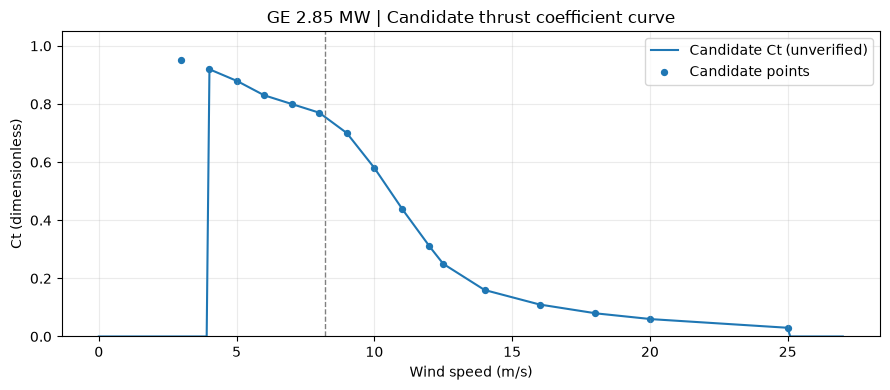

In [2]:
ROTOR_DIAMETER_M = 103.0
HUB_HEIGHT_M = 85.0
RATED_POWER_KW = 2850.0
CUT_IN_MS = 4.0
CUT_OUT_MS = 25.0
REFERENCE_DENSITY = 1.02  # kg/m^3 in supplied reference power curve

CT_SPEEDS = np.array([3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12.5, 14, 16, 18, 20, 25.0])
CT_POINTS = np.array([.95, .92, .88, .83, .80, .77, .70, .58,
                      .44, .31, .25, .16, .11, .08, .06, .03])


def candidate_ct(u):
    a = np.asarray(u, dtype=float)
    result = np.interp(a, CT_SPEEDS, CT_POINTS)
    result = np.where((a < CUT_IN_MS) | (a >= CUT_OUT_MS), 0.0, result)
    return float(result) if result.ndim == 0 else result


scada = pd.read_parquet(PROCESSED_DIR / "scada_data.parquet").copy()
if "turbine" not in scada or "utc" not in scada:
    raise KeyError("SCADA requires turbine and utc columns; check processed schema")
scada["turbine"] = scada["turbine"].map(normal_id)
scada["timestamp"] = to_utc_naive(scada["utc"])
scada = scada[scada["turbine"].isin(LIDAR_TURBINES)].copy()

scada_numeric = ["wind_speed", "real_power_ac", "air_density",
                 "wind_direction", "wind_direction_relative", "nacelle_pos"]
for c in scada_numeric:
    if c not in scada.columns:
        scada[c] = np.nan
    scada[c] = pd.to_numeric(scada[c], errors="coerce")

if scada.duplicated(["timestamp", "turbine"]).any():
    raise ValueError("Repeated SCADA timestamps per turbine. Resolve duplicates explicitly.")

coords = pd.read_csv(find_input("turbine_coordinate_ALTA10.csv"))
coords["turbine"] = coords["Turbine_ID"].map(normal_id)
for c in ["Latitude", "Longitude"]:
    coords[c] = pd.to_numeric(coords[c], errors="coerce")
coords = coords[["turbine", "Latitude", "Longitude"]].dropna().drop_duplicates("turbine")

curve = pd.read_csv(find_input("GE_2_85MW_103mRD_PC.csv"))
curve.columns = curve.columns.str.strip()
for c in ["WINDSPEED", "POWER_KW", "AIR_DENSITY"]:
    curve[c] = pd.to_numeric(curve[c], errors="coerce")
curve = curve[
    np.isclose(curve["AIR_DENSITY"], REFERENCE_DENSITY, atol=.001) &
    curve["TI_CLASS"].astype(str).str.strip().str.lower().eq("normal")
].copy()
curve = (curve.groupby("WINDSPEED", as_index=False)["POWER_KW"]
         .mean().sort_values("WINDSPEED"))
if len(curve) < 2:
    raise ValueError("Insufficient points in the supplied GE reference power curve")

print(f"SCADA records: {len(scada):,} | coordinate sites: {len(coords)}")
print(f"Reference curve: {len(curve)} points, density {REFERENCE_DENSITY} kg/m³")
display(curve.head())

fig, ax = plt.subplots(figsize=(9, 4))
xct = np.linspace(0, 27, 270)
ax.plot(xct, candidate_ct(xct), label="Candidate Ct (unverified)")
ax.scatter(CT_SPEEDS, CT_POINTS, s=18, label="Candidate points")
ax.axvline(FREE_STREAM_SPEED, ls="--", lw=1, color="gray")
ax.set(xlabel="Wind speed (m/s)", ylabel="Ct (dimensionless)",
       title="GE 2.85 MW | Candidate thrust coefficient curve")
ax.set_ylim(0, 1.05); ax.grid(alpha=.25); ax.legend()
finish_plot(fig, "01_candidate_ct")


## 3. Build 10-minute LiDAR statistics from all daily 1-second CSVs

The old analysis used >=540/600 plausible LiDAR seconds, mean speed >=3 m/s,
and LiDAR speed within 0–35 m/s. We reproduce that historical definition.
Each day's 144 10-minute periods remains present, even if it fails screening.

Also record *exploratory* anomalous-low-LiDAR seconds where simultaneous
Sensor 1 >20 m/s and LiDAR <8 m/s (both between 0 and 50 m/s). An interval
is QC-flagged if at least 120 eligible high-Sensor-1 seconds exist AND at
least 50% of these meet the discrepancy condition. Do not treat the flag as
a verified instrument fault.

In [3]:
def process_lidar_day(path, turbine):
    needed = {"timestamp", "lidar_wsp", "sensor1_wsp"}
    optional = {"Vlos1", "Vlos2", "mode", "lidar_phi"}
    df = pd.read_csv(path, usecols=lambda c: c in needed | optional)
    if not needed.issubset(df.columns):
        raise ValueError(f"Missing required LiDAR columns in {path.name}")
    df["timestamp"] = to_utc_naive(df["timestamp"])
    df = df.dropna(subset=["timestamp"]).sort_values("timestamp")
    if df["timestamp"].duplicated().any():
        warnings.warn(f"Duplicate LiDAR seconds in {path}; preserving first record")
        df = df.drop_duplicates("timestamp", keep="first")
    for c in needed - {"timestamp"}:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    lidar = df["lidar_wsp"]
    sensor = df["sensor1_wsp"]
    paired = lidar.between(0, 50) & sensor.between(0, 50)
    high = paired & sensor.gt(20)
    flag = high & lidar.lt(8)
    df["valid_lidar_speed"] = lidar.where(lidar.between(0, 35))
    df["high_sensor"] = high.astype("int8")
    df["flagged_second"] = flag.astype("int8")

    daily = df.set_index("timestamp").resample("10min").agg(
        total_records=("lidar_wsp", "size"),
        valid_seconds=("valid_lidar_speed", "count"),
        mean_speed=("valid_lidar_speed", "mean"),
        std_speed=("valid_lidar_speed", "std"),
        high_sensor_seconds=("high_sensor", "sum"),
        flagged_seconds=("flagged_second", "sum"),
    )
    # Keep 144 slots/day: count data availability and prevent silently
    # dropping data-starved intervals.
    date = pd.Timestamp(path.stem)
    full_index = pd.date_range(date, periods=144, freq="10min")
    daily = daily.reindex(full_index)
    daily.index.name = "timestamp"
    for col in ["total_records", "valid_seconds", "high_sensor_seconds", "flagged_seconds"]:
        daily[col] = daily[col].fillna(0).astype("int32")
    daily["valid_interval"] = (
        daily["valid_seconds"].ge(MIN_LIDAR_VALID_SECONDS) &
        daily["mean_speed"].ge(MIN_LIDAR_MEAN_MS)
    )
    daily["TI"] = (daily["std_speed"] / daily["mean_speed"]).where(daily["valid_interval"])
    daily["k_proxy"] = .5 * daily["TI"]  # sensitivity proxy, not calibrated physics
    frac = daily["flagged_seconds"] / daily["high_sensor_seconds"].replace(0, np.nan)
    daily["suspicious_fraction"] = frac
    daily["flagged_interval"] = (daily["high_sensor_seconds"].ge(120) & frac.ge(.5))
    daily["turbine"] = turbine
    return daily.reset_index()


lidar_parts = []
file_records = []
for turbine in LIDAR_TURBINES:
    daily_files = sorted((LIDAR_DIR / f"WTG_T{turbine[3:]}").glob("*.csv"))
    if MAX_FILES_PER_TURBINE is not None:
        daily_files = daily_files[:MAX_FILES_PER_TURBINE]
    if not daily_files:
        raise FileNotFoundError(f"No LiDAR daily CSVs found for {turbine} under {LIDAR_DIR}")
    for f in daily_files:
        lidar_parts.append(process_lidar_day(f, turbine))
    file_records.append({"turbine": turbine, "files": len(daily_files)})
    print(f"Processed {turbine}: {len(daily_files)} daily files")

lidar_intervals = pd.concat(lidar_parts, ignore_index=True)
file_counts = pd.DataFrame(file_records)
if lidar_intervals.duplicated(["timestamp", "turbine"]).any():
    raise ValueError("Duplicate 10-minute intervals between LiDAR daily files")

valid_lidar = lidar_intervals[lidar_intervals["valid_interval"]].copy()
ti_summary = lidar_intervals.groupby("turbine", as_index=False).agg(
    all_intervals=("valid_interval", "size"),
    valid_intervals=("valid_interval", "sum"),
    mean_TI=("TI", "mean"),
    median_TI=("TI", "median"),
    mean_k_proxy=("k_proxy", "mean"),
    median_k_proxy=("k_proxy", "median"),
    flagged_intervals=("flagged_interval", "sum"),
    flagged_seconds=("flagged_seconds", "sum"),
)
speed_means = valid_lidar.groupby("turbine")["mean_speed"].mean().rename("mean_speed_ms")
ti_summary = ti_summary.join(speed_means, on="turbine").merge(file_counts, on="turbine")
ti_summary["coverage_pct"] = 100 * ti_summary["valid_intervals"] / ti_summary["all_intervals"]
ti_summary["mean_TI_pct"] = 100 * ti_summary["mean_TI"]
ti_summary["median_TI_pct"] = 100 * ti_summary["median_TI"]
print("\nSIX-TURBINE LIDAR TI SUMMARY")
display(ti_summary.round(4))
save_table(ti_summary, "02_ti_six_turbines")
save_table(lidar_intervals, "02_lidar_all_10min")


Processed WTG159: 134 daily files
Processed WTG170: 133 daily files
Processed WTG171: 134 daily files
Processed WTG173: 134 daily files
Processed WTG180: 133 daily files
Processed WTG184: 134 daily files

SIX-TURBINE LIDAR TI SUMMARY


,turbine,all_intervals,valid_intervals,mean_TI,median_TI,mean_k_proxy,median_k_proxy,flagged_intervals,flagged_seconds,mean_speed_ms,files,coverage_pct,mean_TI_pct,median_TI_pct
0,WTG159,19296,15165,0.1139,0.1001,0.0569,0.0500,126,51794,10.2995,134,78.5914,11.3871,10.0075
1,WTG170,19152,14866,0.1454,0.1353,0.0727,0.0677,2,1017,9.3547,133,77.6211,14.5378,13.5327
2,WTG171,19296,14965,0.1559,0.1494,0.0779,0.0747,11,4493,8.8352,134,77.5549,15.5892,14.9416
3,WTG173,19296,14551,0.1561,0.1559,0.0780,0.0779,8,3984,8.9574,134,75.4094,15.6054,15.5892
4,WTG180,19152,15189,0.1322,0.1164,0.0661,0.0582,0,34,10.7603,133,79.3076,13.2170,11.6411
5,WTG184,19296,14675,0.1476,0.1434,0.0738,0.0717,0,7,8.8604,134,76.0520,14.7642,14.3444


## 4. TI comparisons and spatial distribution

- Comparing the full six datasets can mix different wind conditions.
- Therefore compare *identical 10-minute timestamps* with each turbine's
  local speed restricted to 7–13 m/s (a broad exploratory band).
- A difference in local TI is NOT itself a measurement of a local Jensen k.

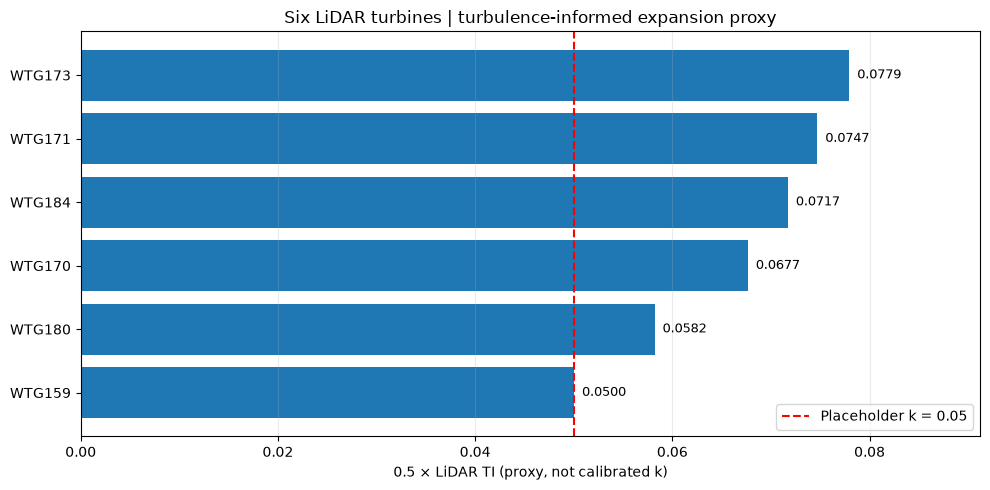

Same-time intervals with all six: 8,387
All six additionally between 7 and 13 m/s: 2,509


,turbine,median_TI_pct,mean_TI_pct,n_10min
0,WTG159,9.475,10.024,2509
1,WTG170,10.418,10.860,2509
2,WTG171,12.219,12.660,2509
3,WTG173,14.633,14.152,2509
4,WTG180,10.595,11.279,2509
5,WTG184,12.132,12.478,2509


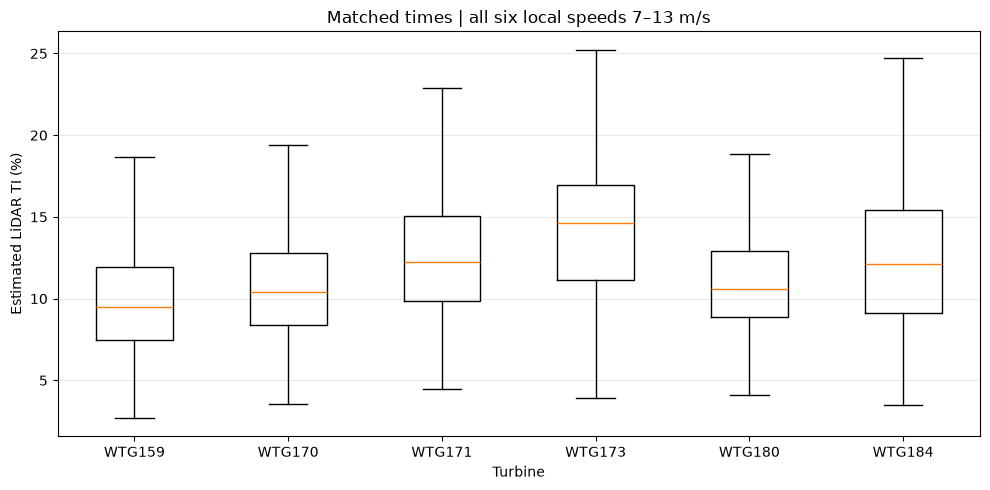

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sort_ti = ti_summary.sort_values("median_k_proxy")
ax.barh(sort_ti.turbine, sort_ti.median_k_proxy)
ax.axvline(BASELINE_K, color="red", ls="--", label="Placeholder k = 0.05")
for idx, (_, rec) in enumerate(sort_ti.iterrows()):
    ax.text(rec.median_k_proxy + .0008, idx, f"{rec.median_k_proxy:.4f}", va="center", fontsize=9)
ax.set(xlabel="0.5 × LiDAR TI (proxy, not calibrated k)",
       title="Six LiDAR turbines | turbulence-informed expansion proxy")
ax.set_xlim(0, max(.085, sort_ti.median_k_proxy.max() * 1.17))
ax.legend(); ax.grid(axis="x", alpha=.25)
finish_plot(fig, "03_turbulence_k_proxy_comparison")

speed_wide = valid_lidar.pivot(index="timestamp", columns="turbine", values="mean_speed").reindex(columns=LIDAR_TURBINES)
ti_wide = valid_lidar.pivot(index="timestamp", columns="turbine", values="TI").reindex(columns=LIDAR_TURBINES)
all_six = speed_wide.notna().all(axis=1) & ti_wide.notna().all(axis=1)
all_six_band = all_six & speed_wide.ge(7).all(axis=1) & speed_wide.le(13).all(axis=1)
matched_ti = ti_wide.loc[all_six_band]
print(f"Same-time intervals with all six: {all_six.sum():,}")
print(f"All six additionally between 7 and 13 m/s: {all_six_band.sum():,}")
if not matched_ti.empty:
    comparison = pd.DataFrame({
        "turbine": LIDAR_TURBINES,
        "median_TI_pct": [100 * matched_ti[c].median() for c in LIDAR_TURBINES],
        "mean_TI_pct": [100 * matched_ti[c].mean() for c in LIDAR_TURBINES],
        "n_10min": [matched_ti[c].count() for c in LIDAR_TURBINES]
    })
    display(comparison.round(3))
    save_table(comparison, "03_matched_time_TI")
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot([100 * matched_ti[c].dropna() for c in LIDAR_TURBINES],
               tick_labels=LIDAR_TURBINES, showfliers=False)
    ax.set(xlabel="Turbine", ylabel="Estimated LiDAR TI (%)",
           title="Matched times | all six local speeds 7–13 m/s")
    ax.grid(axis="y", alpha=.25)
    finish_plot(fig, "03_matched_turbulence_boxplot")
else:
    print("No common intervals under selected wind-speed restriction")


## 5. LiDAR anomaly diagnostics and sensitivity

The flags are *not* instrument certified. They compare LiDAR reconstruction
against a sensor stream of not-yet-verified origin. Examine the event dates,
coverage, mode, and LOS data with sponsor before deciding which values to
exclude from a scientific analysis.

WTG159 MOST-IMPACTED DATES (min. 600 eligible seconds):


C:\Users\alex-\AppData\Local\Temp\ipykernel_17400\2893095553.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .nlargest(12, "flagged_pct_eligible").round(2))


,turbine,date,high_sensor_seconds,flagged_seconds,flagged_intervals,flagged_pct_eligible
38,WTG159,2026-06-08,25776,24273,71,94.17
30,WTG159,2026-05-31,1536,1380,4,89.84
16,WTG159,2026-05-17,52374,15750,28,30.07
15,WTG159,2026-05-16,44643,7959,18,17.83
57,WTG159,2026-06-27,14418,588,2,4.08
37,WTG159,2026-06-07,15213,289,1,1.90
39,WTG159,2026-06-09,34226,501,2,1.46
13,WTG159,2026-05-14,25803,159,0,0.62
59,WTG159,2026-06-29,13863,83,0,0.60
14,WTG159,2026-05-15,33142,164,0,0.49



WTG159 TI QUALITY-SCREENING SENSITIVITY


,scenario,n,mean_TI_pct,median_TI_pct,median_k_proxy
0,All valid 10-min intervals,15165,11.3871,10.0075,0.05
1,Exclude flagged intervals,15075,11.3763,10.0075,0.05


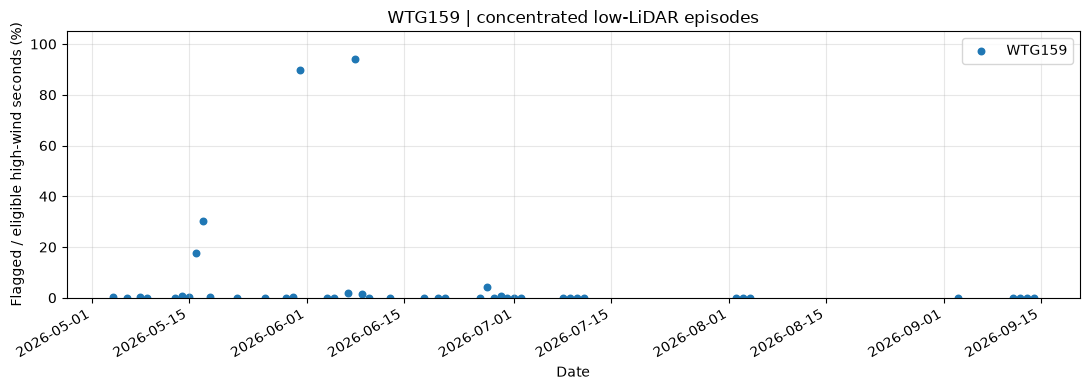

In [5]:
qc_events = lidar_intervals.copy()
qc_events["date"] = qc_events["timestamp"].dt.normalize()
qc_daily = qc_events.groupby(["turbine", "date"], as_index=False).agg(
    high_sensor_seconds=("high_sensor_seconds", "sum"),
    flagged_seconds=("flagged_seconds", "sum"),
    flagged_intervals=("flagged_interval", "sum")
)
qc_daily["flagged_pct_eligible"] = 100 * qc_daily["flagged_seconds"] / qc_daily["high_sensor_seconds"].replace(0, np.nan)
print("WTG159 MOST-IMPACTED DATES (min. 600 eligible seconds):")
display(qc_daily[(qc_daily.turbine == "WTG159") & (qc_daily.high_sensor_seconds >= 600)]
        .nlargest(12, "flagged_pct_eligible").round(2))
save_table(qc_daily, "04_daily_anomaly_flags")

base159 = valid_lidar[valid_lidar.turbine.eq("WTG159")]
clean159 = base159[~base159.flagged_interval]
qc_sensitivity = pd.DataFrame([
    {"scenario": label, "n": len(frame), "mean_TI_pct": 100 * frame.TI.mean(),
     "median_TI_pct": 100 * frame.TI.median(), "median_k_proxy": frame.k_proxy.median()}
    for label, frame in [("All valid 10-min intervals", base159),
                         ("Exclude flagged intervals", clean159)]
])
print("\nWTG159 TI QUALITY-SCREENING SENSITIVITY")
display(qc_sensitivity.round(4))
save_table(qc_sensitivity, "04_wtg159_TI_sensitivity")

fig, ax = plt.subplots(figsize=(11, 4))
for turbine in ["WTG159"]:
    df = qc_daily[(qc_daily.turbine == turbine) & (qc_daily.high_sensor_seconds >= 600)]
    ax.scatter(df.date, df.flagged_pct_eligible, s=22, label=turbine)
ax.set(xlabel="Date", ylabel="Flagged / eligible high-wind seconds (%)",
       title="WTG159 | concentrated low-LiDAR episodes")
ax.set_ylim(0, 105); ax.grid(alpha=.3); ax.legend()
fig.autofmt_xdate()
finish_plot(fig, "04_WTG159_anomalies_by_date")


### Event-specific beam and sensor diagnostics (WTG159)

This visualization revisits June 8, 2026. Prior examination found `Vlos1`,
`Vlos2`, and `lidar_wsp` changing abruptly while `sensor1_wsp` remained high.
Mode oscillation occurred on both sides of the change; its meaning is unknown.

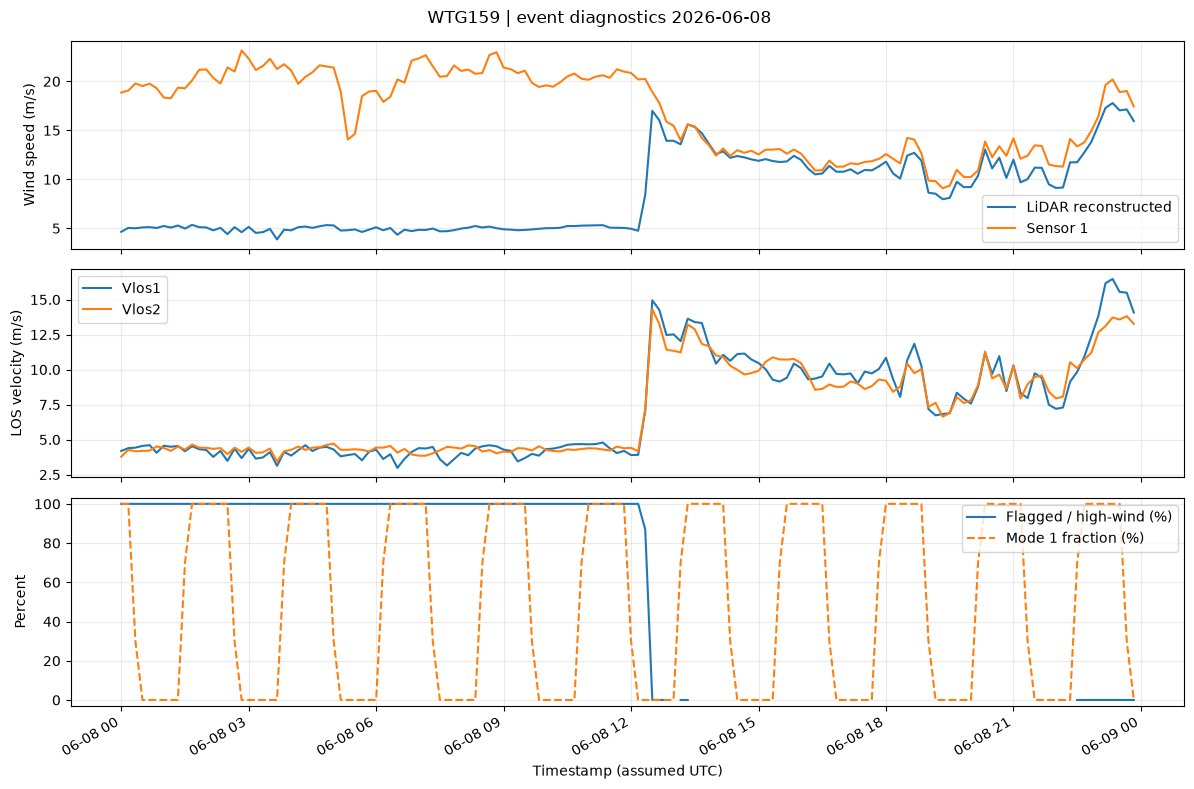

In [6]:
EVENT_DAY = "2026-06-08"  # change to 2026-05-17 for another event
beam_file = LIDAR_DIR / "WTG_T159" / (EVENT_DAY + ".csv")
if beam_file.exists():
    beam = pd.read_csv(beam_file, usecols=lambda c: c in {
        "timestamp", "lidar_wsp", "sensor1_wsp", "Vlos1", "Vlos2", "mode"})
    beam["timestamp"] = to_utc_naive(beam["timestamp"])
    for col in ["lidar_wsp", "sensor1_wsp", "Vlos1", "Vlos2", "mode"]:
        beam[col] = pd.to_numeric(beam[col], errors="coerce")
    beam["mode1"] = beam["mode"].eq(1).astype(float)
    beam["eligible"] = (
        beam["lidar_wsp"].between(0, 50) &
        beam["sensor1_wsp"].between(20, 50)
    ).astype(int)
    beam["flagged"] = ((beam["eligible"] == 1) & (beam["lidar_wsp"] < 8)).astype(int)
    beam_10 = beam.set_index("timestamp").resample("10min").agg(
        lidar_speed=("lidar_wsp", "mean"), sensor1_speed=("sensor1_wsp", "mean"),
        vlos1=("Vlos1", "mean"), vlos2=("Vlos2", "mean"),
        high_count=("eligible", "sum"), flagged_count=("flagged", "sum"),
        mode1_fraction=("mode1", "mean"))
    beam_10["flag_pct"] = 100 * beam_10.flagged_count / beam_10.high_count.replace(0, np.nan)
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(beam_10.index, beam_10.lidar_speed, label="LiDAR reconstructed")
    axes[0].plot(beam_10.index, beam_10.sensor1_speed, label="Sensor 1")
    axes[0].set_ylabel("Wind speed (m/s)"); axes[0].legend(); axes[0].grid(alpha=.25)
    axes[1].plot(beam_10.index, beam_10.vlos1, label="Vlos1")
    axes[1].plot(beam_10.index, beam_10.vlos2, label="Vlos2")
    axes[1].set_ylabel("LOS velocity (m/s)"); axes[1].legend(); axes[1].grid(alpha=.25)
    axes[2].plot(beam_10.index, beam_10.flag_pct, label="Flagged / high-wind (%)")
    axes[2].plot(beam_10.index, beam_10.mode1_fraction * 100, "--", label="Mode 1 fraction (%)")
    axes[2].set(xlabel="Timestamp (assumed UTC)", ylabel="Percent", ylim=(-3, 103))
    axes[2].legend(); axes[2].grid(alpha=.25)
    fig.suptitle(f"WTG159 | event diagnostics {EVENT_DAY}")
    fig.autofmt_xdate()
    finish_plot(fig, "04_WTG159_event_beam_mode")
else:
    print(f"Skipping event plot; {beam_file} not found")


## 6. Wind-speed comparison: matched SCADA + LiDAR

Timestamps are *assumed* UTC in both sources, and 10-minute labels are
*assumed* to refer to the same averaging window. This is unverified.
Sign convention: `SCADA minus LiDAR` >0 means SCADA reports faster wind.

Matched SCADA+LiDAR intervals: 88,934


,turbine,scenario,observations,mean_diff_ms,median_diff_ms,MAE_ms,RMSE_ms
0,WTG159,All quality-filtered LiDAR intervals,15018,1.710,1.310,1.752,2.811
1,WTG170,All quality-filtered LiDAR intervals,14791,0.538,0.473,0.620,0.939
2,WTG171,All quality-filtered LiDAR intervals,14782,0.388,0.468,0.658,0.830
3,WTG173,All quality-filtered LiDAR intervals,14480,0.306,0.195,0.593,1.148
4,WTG180,All quality-filtered LiDAR intervals,15188,-0.108,-0.032,0.509,0.726
5,WTG184,All quality-filtered LiDAR intervals,14675,0.511,0.513,0.638,0.783
6,WTG159,Exclude anomaly-flagged,14934,1.596,1.306,1.638,2.264
7,WTG170,Exclude anomaly-flagged,14790,0.537,0.473,0.619,0.927
8,WTG171,Exclude anomaly-flagged,14782,0.388,0.468,0.658,0.830
9,WTG173,Exclude anomaly-flagged,14473,0.299,0.194,0.587,1.103


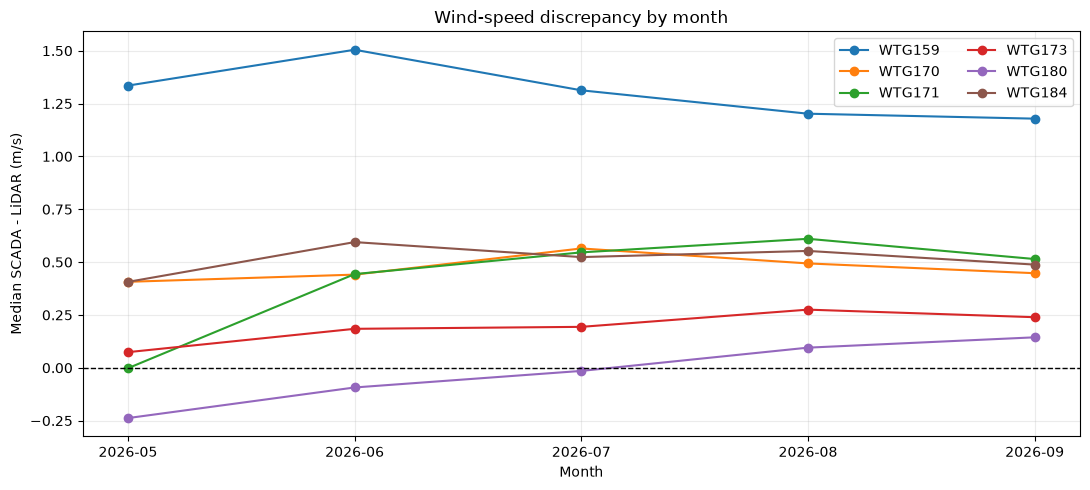

In [7]:
lidar_compare = valid_lidar[["timestamp", "turbine", "mean_speed", "TI", "flagged_interval"]].rename(
    columns={"mean_speed": "lidar_speed"}
)
scada_compare = scada[["timestamp", "turbine", "wind_speed", "real_power_ac", "air_density",
                       "wind_direction", "wind_direction_relative", "nacelle_pos"]].rename(
    columns={"wind_speed": "scada_speed", "real_power_ac": "power_kw"}
)
all_matched = lidar_compare.merge(scada_compare, on=["timestamp", "turbine"],
                                   how="inner", validate="one_to_one")
all_matched = all_matched[
    all_matched["scada_speed"].between(0, 35) &
    all_matched["lidar_speed"].notna()
].copy()
all_matched["speed_diff"] = all_matched["scada_speed"] - all_matched["lidar_speed"]
all_matched["generation_screened"] = (
    all_matched["scada_speed"].between(4, 25, inclusive="left") &
    all_matched["lidar_speed"].between(3, 25) &
    all_matched["power_kw"].between(100, RATED_POWER_KW * 1.05)
)


def summarize_speed(frame, name):
    rows = []
    for turbine, g in frame.groupby("turbine"):
        d = g.speed_diff
        rows.append({"turbine": turbine, "scenario": name, "observations": len(g),
                     "mean_diff_ms": d.mean(), "median_diff_ms": d.median(),
                     "MAE_ms": d.abs().mean(), "RMSE_ms": np.sqrt(np.mean(d**2))})
    return pd.DataFrame(rows)


speed_summary = pd.concat([
    summarize_speed(all_matched, "All quality-filtered LiDAR intervals"),
    summarize_speed(all_matched[~all_matched.flagged_interval], "Exclude anomaly-flagged"),
    summarize_speed(all_matched[all_matched.generation_screened], "Generation-screened"),
], ignore_index=True)
print(f"Matched SCADA+LiDAR intervals: {len(all_matched):,}")
display(speed_summary.round(3))
save_table(speed_summary, "05_speed_comparison_and_sensitivity")
save_table(all_matched, "05_scada_lidar_matched")

fig, ax = plt.subplots(figsize=(11, 5))
monthly = all_matched.assign(month=all_matched.timestamp.dt.to_period("M").astype(str))
monthly = monthly.groupby(["turbine", "month"], as_index=False).agg(
    median_diff=("speed_diff", "median"), observations=("speed_diff", "size"))
for turbine, group in monthly.groupby("turbine"):
    ax.plot(group.month, group.median_diff, marker="o", label=turbine)
ax.axhline(0, ls="--", color="black", lw=1)
ax.set(xlabel="Month", ylabel="Median SCADA - LiDAR (m/s)",
       title="Wind-speed discrepancy by month")
ax.grid(alpha=.25); ax.legend(ncol=2)
finish_plot(fig, "05_monthly_wind_speed_difference")


## 7. Wind-direction consistency (do NOT apply automated offset corrections)

Historical observation: 
`wind_direction ~= (nacelle_pos + wind_direction_relative) % 360`.
Nacelle headings still disagree across turbines; this prevents verified
wake-exposure assignments. Even high daily circular consistency does not
validate absolute geographic headings, particularly on sparse days.

In [8]:
direction_records = scada_compare.dropna(subset=["timestamp"]).copy()
reconstructed = (direction_records.nacelle_pos + direction_records.wind_direction_relative) % 360
direction_records["reconstruction_error_deg"] = circular_difference(
    direction_records.wind_direction, reconstructed)
direction_reconstruction = direction_records.groupby("turbine", as_index=False).agg(
    observations=("reconstruction_error_deg", "count"),
    median_absolute_error_deg=("reconstruction_error_deg", lambda s: s.abs().median())
)
print("SCADA DIRECTION INTERNAL CONSISTENCY")
display(direction_reconstruction.round(2))
save_table(direction_reconstruction, "06_direction_internal_consistency")

wind_pivot = scada_compare.pivot(index="timestamp", columns="turbine", values="wind_direction")
wind_pivot = wind_pivot.reindex(columns=LIDAR_TURBINES).dropna()
direction_offset_rows = []
for other in LIDAR_TURBINES[1:]:
    d = circular_difference(wind_pivot[other], wind_pivot["WTG159"])
    offset, concentration = circular_stats(d)
    direction_offset_rows.append({
        "turbine": other, "ref": "WTG159", "simultaneous_periods": len(d),
        "circular_mean_diff_deg": offset, "R": concentration,
        "median_abs_difference_deg": np.median(np.abs(d))
    })
direction_offsets = pd.DataFrame(direction_offset_rows)
print("\nSIMULTANEOUS DIRECTION DIFFERENCES (NOT CORRECTION FACTORS)")
display(direction_offsets.round(2))
save_table(direction_offsets, "06_direction_cross_turbine_uncertainty")


SCADA DIRECTION INTERNAL CONSISTENCY


,turbine,observations,median_absolute_error_deg
0,WTG159,29786,1.28
1,WTG170,30706,1.49
2,WTG171,32424,1.71
3,WTG173,31962,1.65
4,WTG180,33727,1.75
5,WTG184,32711,1.94



SIMULTANEOUS DIRECTION DIFFERENCES (NOT CORRECTION FACTORS)


,turbine,ref,simultaneous_periods,circular_mean_diff_deg,R,median_abs_difference_deg
0,WTG170,WTG159,35527,167.43,0.44,144.87
1,WTG171,WTG159,35527,173.48,0.37,140.82
2,WTG173,WTG159,35527,-126.83,0.27,103.99
3,WTG180,WTG159,35527,-89.82,0.33,92.62
4,WTG184,WTG159,35527,165.91,0.32,127.49


### Direction-sensitive TI (provisional SCADA wind-from assumption)

We can visualize TI by reported direction but cannot assign validated wake
sectors without confirming SCADA geographic references. Require at least 20
simultaneous intervals per 30-degree sector per turbine. Use our selected
common-speed 7–13 m/s timestamps to reduce differences in weather sampling.

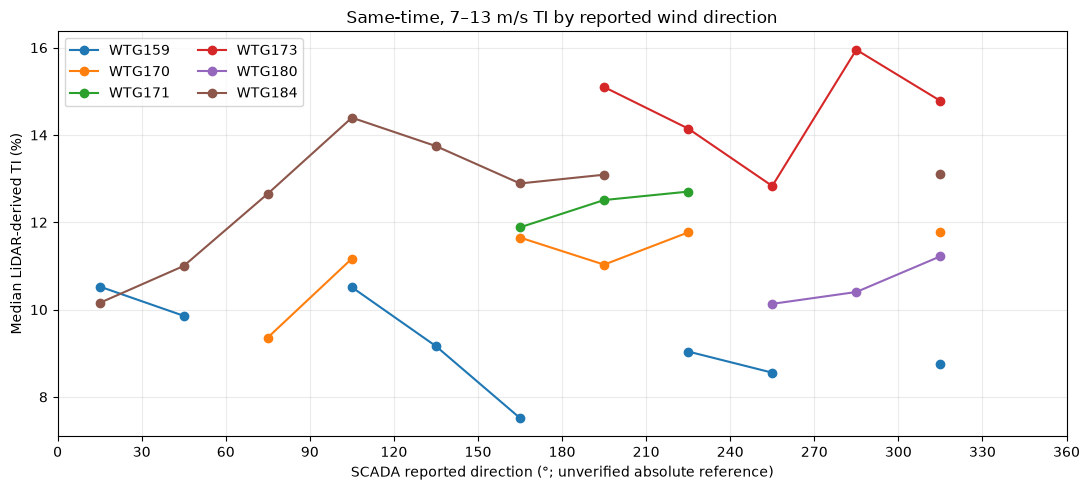

In [9]:
if not matched_ti.empty:
    dir_ti = all_matched[
        all_matched["timestamp"].isin(matched_ti.index) &
        all_matched.wind_direction.between(0, 360)
    ].copy()
    dir_ti["sector_center"] = (
        (np.floor((dir_ti.wind_direction % 360) / 30).astype(int) * 30) + 15
    )
    dir_summary = dir_ti.groupby(["turbine", "sector_center"], as_index=False).agg(
        n=("TI", "count"), median_TI_pct=("TI", lambda t: 100 * t.median()))
    dir_summary.loc[dir_summary.n.lt(20), "median_TI_pct"] = np.nan
    save_table(dir_summary, "06_directional_TI_unverified_axis")
    fig, ax = plt.subplots(figsize=(11, 5))
    for turbine, group in dir_summary.groupby("turbine"):
        ordered = group.set_index("sector_center").reindex(np.arange(15, 360, 30))
        ax.plot(ordered.index, ordered.median_TI_pct, marker="o", label=turbine)
    ax.set(xlabel="SCADA reported direction (°; unverified absolute reference)",
           ylabel="Median LiDAR-derived TI (%)",
           title="Same-time, 7–13 m/s TI by reported wind direction")
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 30))
    ax.grid(alpha=.25); ax.legend(ncol=2)
    finish_plot(fig, "06_ti_vs_reported_wind_direction")
else:
    print("Skipping direction-by-TI chart: no common-speed intervals")


### Optional WTG159 `lidar_phi` direction convention check

On the first available WTG159 day, circular-average raw `lidar_phi` by
10-minute interval. Check both plus/minus-nacelle candidates against reported
SCADA wind direction. An error minimum alone does **not** validate geographic
heading (especially if SCADA wind direction is nacelle-derived).

In [10]:
phi_files = sorted((LIDAR_DIR / "WTG_T159").glob("*.csv"))
if phi_files:
    raw_phi = pd.read_csv(phi_files[0], usecols=lambda c: c in {"timestamp", "lidar_phi"})
    if {"timestamp", "lidar_phi"}.issubset(raw_phi.columns):
        raw_phi["timestamp"] = to_utc_naive(raw_phi["timestamp"])
        raw_phi["lidar_phi"] = pd.to_numeric(raw_phi["lidar_phi"], errors="coerce")
        angles = np.deg2rad(raw_phi["lidar_phi"])
        raw_phi["s"] = np.sin(angles)
        raw_phi["c"] = np.cos(angles)
        phi_mean = raw_phi.set_index("timestamp").resample("10min")[["s", "c"]].mean()
        phi_mean["phi_deg"] = np.rad2deg(np.arctan2(phi_mean.s, phi_mean.c)) % 360
        scada159dir = scada_compare[scada_compare.turbine.eq("WTG159")].set_index("timestamp")
        test_phi = phi_mean.join(scada159dir[["nacelle_pos", "wind_direction"]], how="inner").dropna()
        candidates = {
            "lidar_phi treated as absolute": test_phi.phi_deg,
            "nacelle + lidar_phi": test_phi.nacelle_pos + test_phi.phi_deg,
            "nacelle - lidar_phi": test_phi.nacelle_pos - test_phi.phi_deg,
        }
        phi_check = pd.DataFrame([
            {"candidate": name, "n": len(test_phi),
             "median_absolute_error_deg": np.median(np.abs(circular_difference(u, test_phi.wind_direction)))}
            for name, u in candidates.items()
        ]).sort_values("median_absolute_error_deg")
        print("WTG159 PHI CONVENTION CHECK (NOT AN EXTERNAL VALIDATION)")
        display(phi_check.round(2))
        save_table(phi_check, "06_wtg159_phi_candidate_check")


WTG159 PHI CONVENTION CHECK (NOT AN EXTERNAL VALIDATION)


,candidate,n,median_absolute_error_deg
2,nacelle - lidar_phi,113,7.34
1,nacelle + lidar_phi,113,7.85
0,lidar_phi treated as absolute,113,33.97


## 8. Reference power curve as a *consistency* test, not ground truth

Supplied `GE_2_85MW_103mRD_PC.csv` is treated as a tabular reference at
density 1.02 kg/m³ and TI class normal; provenance remains to verify.
Matched filter: both reported wind speeds 5–12.5 m/s, power 100–2850 kW,
SCADA air density within 0.99–1.05 kg/m³. This does NOT guarantee normal
power production or account exactly for density/wind shear/rotor effects.
Applying a nonlinear power curve to a 10-minute mean creates additional
aggregation bias. SCADA speed may be derived/adjusted from power.

SIX-TURBINE POWER-CURVE AGREEMENT


,turbine,source,observations,mean_error_kw,MAE_kw,RMSE_kw
0,WTG159,LIDAR,6138,-204.26,207.62,230.67
1,WTG159,SCADA,6138,161.60,176.57,213.79
2,WTG170,LIDAR,8223,-150.72,191.63,223.63
3,WTG170,SCADA,8223,7.42,80.12,109.67
4,WTG171,LIDAR,9420,-132.09,197.09,238.04
5,WTG171,SCADA,9420,64.44,134.63,183.41
6,WTG173,LIDAR,9978,-53.75,145.33,182.50
7,WTG173,SCADA,9978,-1.20,104.68,136.35
8,WTG180,LIDAR,6496,-69.82,118.00,145.77
9,WTG180,SCADA,6496,-0.12,109.29,135.04


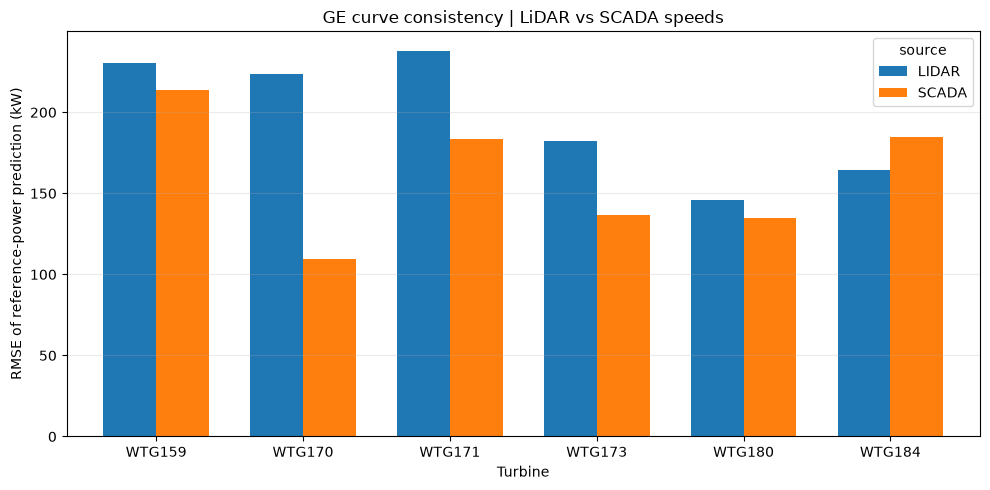

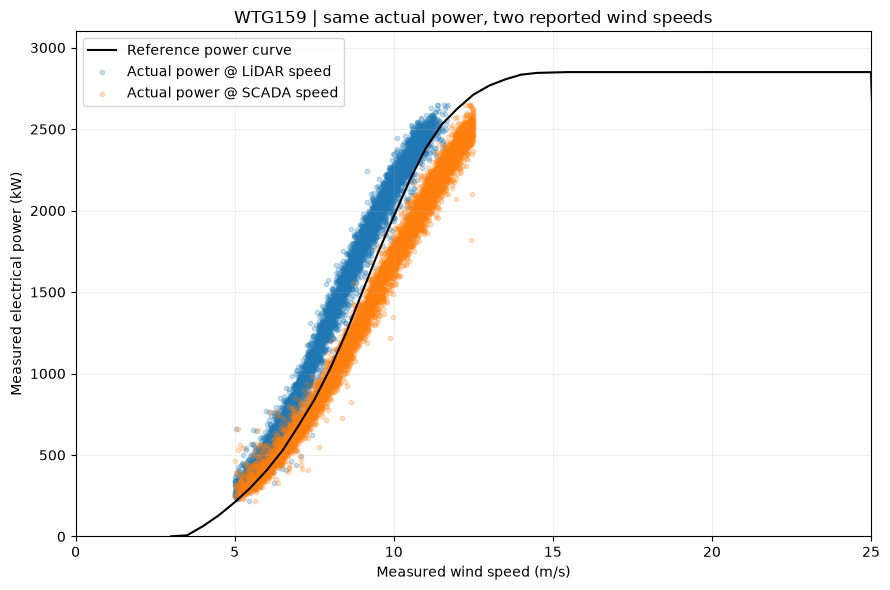

In [11]:
power_data = all_matched[
    all_matched.lidar_speed.between(5, 12.5) &
    all_matched.scada_speed.between(5, 12.5) &
    all_matched.power_kw.between(100, RATED_POWER_KW) &
    all_matched.air_density.between(.99, 1.05)
].copy()

xp = curve.WINDSPEED.to_numpy()
fp = curve.POWER_KW.to_numpy()
if xp.min() > 5 or xp.max() < 12.5:
    raise ValueError("Reference curve does not span our 5–12.5 m/s validation interval")
power_data["pred_lidar_kw"] = np.interp(power_data.lidar_speed, xp, fp)
power_data["pred_scada_kw"] = np.interp(power_data.scada_speed, xp, fp)
power_data["error_lidar_kw"] = power_data.pred_lidar_kw - power_data.power_kw
power_data["error_scada_kw"] = power_data.pred_scada_kw - power_data.power_kw

power_rows = []
for turbine, g in power_data.groupby("turbine"):
    for source in ["lidar", "scada"]:
        e = g[f"error_{source}_kw"]
        power_rows.append({"turbine": turbine, "source": source.upper(),
                           "observations": len(g), "mean_error_kw": e.mean(),
                           "MAE_kw": e.abs().mean(), "RMSE_kw": np.sqrt(np.mean(e**2))})
power_summary = pd.DataFrame(power_rows)
print("SIX-TURBINE POWER-CURVE AGREEMENT")
display(power_summary.round(2))
save_table(power_summary, "07_six_turbine_power_error")
save_table(power_data, "07_filtered_power_prediction_pairs")

if not power_summary.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    rmse = power_summary.pivot(index="turbine", columns="source", values="RMSE_kw")
    rmse = rmse.reindex(LIDAR_TURBINES)
    rmse.plot.bar(ax=ax, width=.72)
    ax.set(xlabel="Turbine", ylabel="RMSE of reference-power prediction (kW)",
           title="GE curve consistency | LiDAR vs SCADA speeds")
    ax.grid(axis="y", alpha=.25); ax.tick_params(axis="x", rotation=0)
    finish_plot(fig, "07_power_rmse_six_turbines")

if not power_data[power_data.turbine.eq("WTG159")].empty:
    g = power_data[power_data.turbine.eq("WTG159")]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(curve.WINDSPEED, curve.POWER_KW, color="black", label="Reference power curve")
    ax.scatter(g.lidar_speed, g.power_kw, alpha=.23, s=10, label="Actual power @ LiDAR speed")
    ax.scatter(g.scada_speed, g.power_kw, alpha=.23, s=10, label="Actual power @ SCADA speed")
    ax.set(xlabel="Measured wind speed (m/s)", ylabel="Measured electrical power (kW)",
           title="WTG159 | same actual power, two reported wind speeds",
           xlim=(0, 25), ylim=(0, 3100))
    ax.grid(alpha=.2); ax.legend()
    finish_plot(fig, "07_WTG159_power_curve")


## 9. Signed power error by wind-speed band

Wind-speed bins use the mean of LiDAR + SCADA as a symmetric display axis.
This is NOT an independently validated true wind speed. Higher-speed bins
have fewer observations; require at least 100 intervals per turbine/bin.

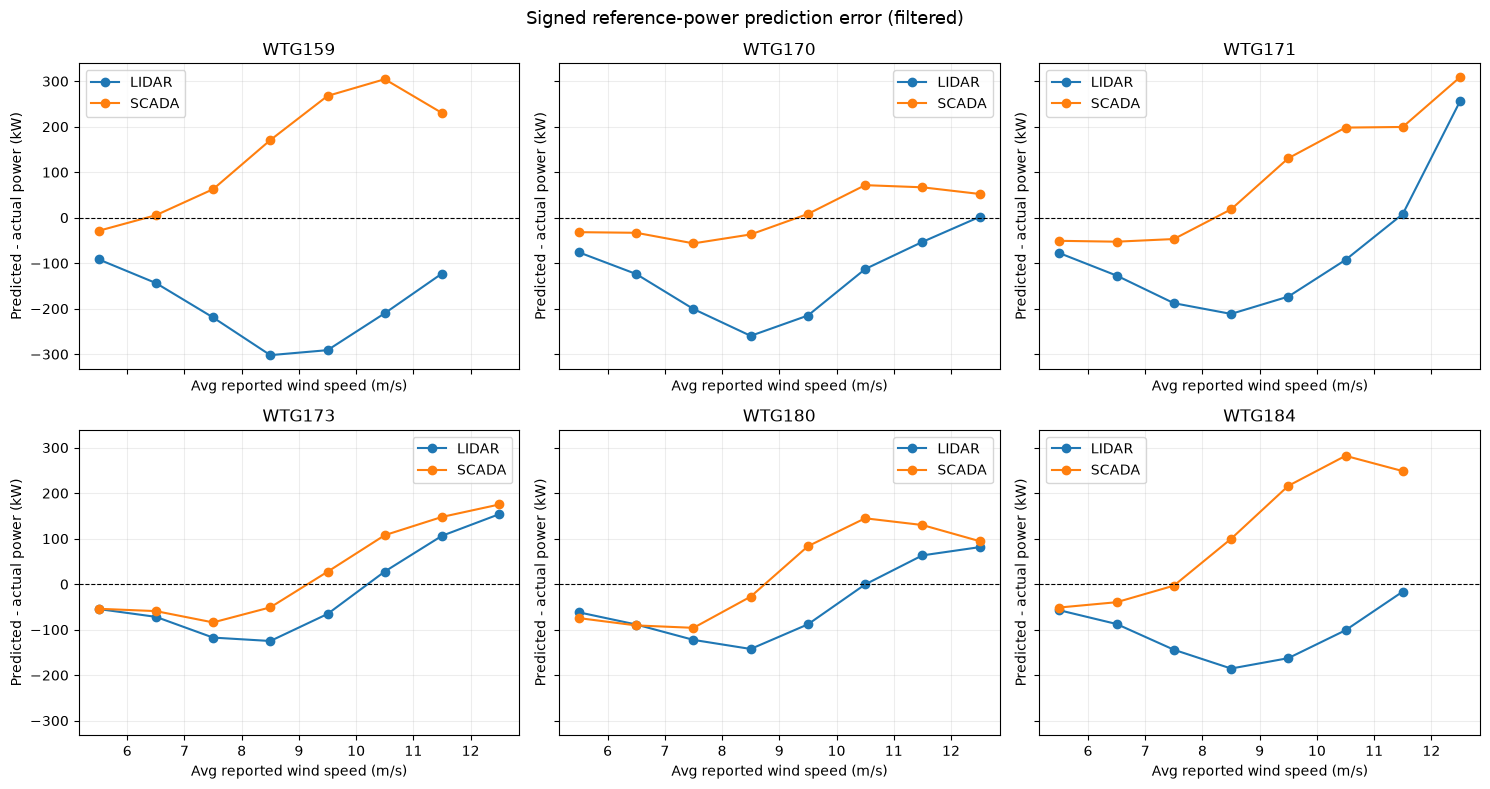

In [12]:
power_data["comparison_speed"] = .5 * (power_data.lidar_speed + power_data.scada_speed)
power_data["speed_bin"] = pd.cut(power_data.comparison_speed,
                                  bins=np.arange(5, 14, 1), right=False)
error_rows = []
for (turbine, interval), group in power_data.groupby(["turbine", "speed_bin"], observed=True):
    for source in ["lidar", "scada"]:
        e = group[f"error_{source}_kw"]
        error_rows.append({"turbine": turbine, "bin_center_ms": interval.left + .5,
                           "source": source.upper(), "n": len(e), "mean_error_kw": e.mean(),
                           "RMSE_kw": np.sqrt(np.mean(e**2))})
error_bins = pd.DataFrame(error_rows)
save_table(error_bins, "08_power_error_by_wind_speed")
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, turbine in zip(axs.flat, LIDAR_TURBINES):
    for source in ["LIDAR", "SCADA"]:
        gg = error_bins[(error_bins.turbine == turbine) &
                        (error_bins.source == source) & (error_bins.n >= 100)]
        ax.plot(gg.bin_center_ms, gg.mean_error_kw, marker="o", label=source)
    ax.axhline(0, color="black", ls="--", lw=.8)
    ax.set(title=turbine, xlabel="Avg reported wind speed (m/s)",
           ylabel="Predicted - actual power (kW)")
    ax.grid(alpha=.22); ax.legend()
fig.suptitle("Signed reference-power prediction error (filtered)", fontsize=13)
finish_plot(fig, "08_power_signed_error_by_speed")


## 10. Turbine locations and USGS terrain overlaid with wake scenarios

**This is a scenario, not a site-validated reconstruction.** Both models
reuse the geometry of notebook 05:
- Meteorological wind-from 231.72 degrees, inflow 8.2 m/s (editable above)
- One candidate Ct for this inflow; identical D=103 m, hub height=85 m
- Jensen top-hat or Gaussian-**style** deficit (not a full published Gaussian)
- Geometric vertical separation using USGS DEM; *no terrain-flow field*
- Quadratic deficit superposition; no yaw, shear, rotor averaging or
  independently validated wind direction.
- Colored markers show **measured TI-derived k proxies** and do **NOT** alter
  the baseline wake calculation (`BASELINE_K=0.05`).

Terrain/wake scenario: 47 sites, 6 with LiDAR, grid 606x521


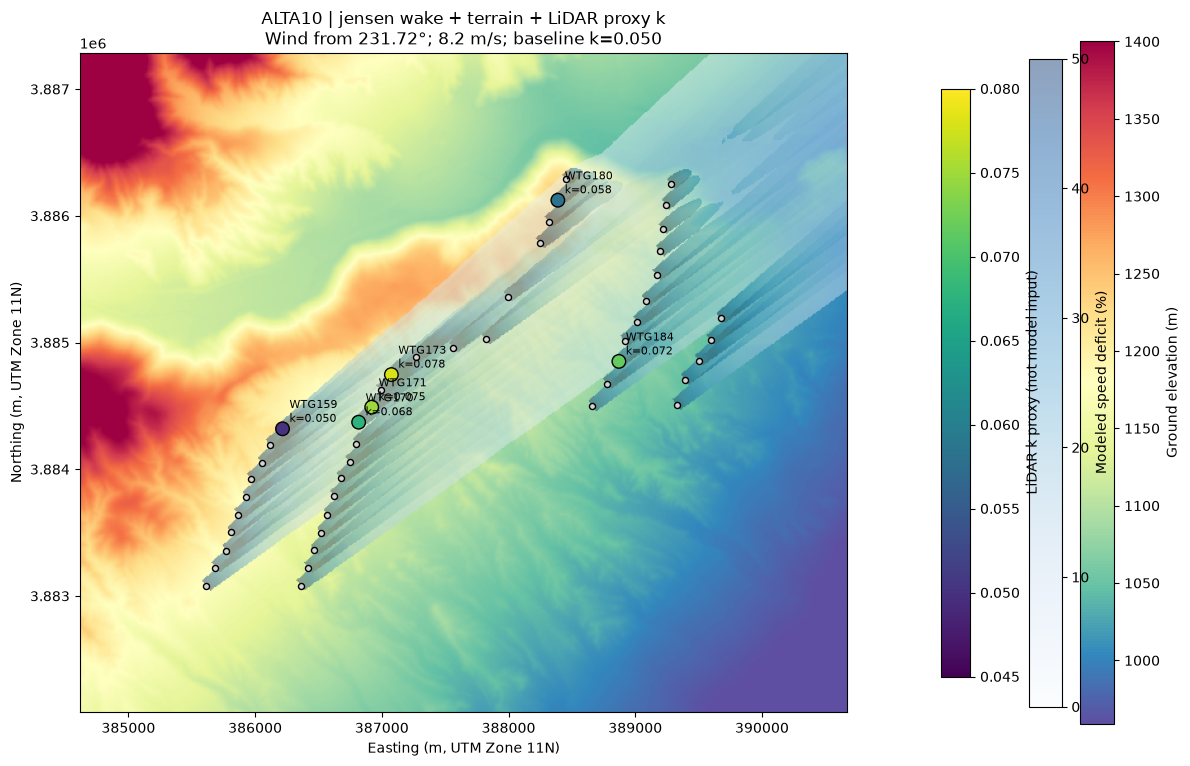

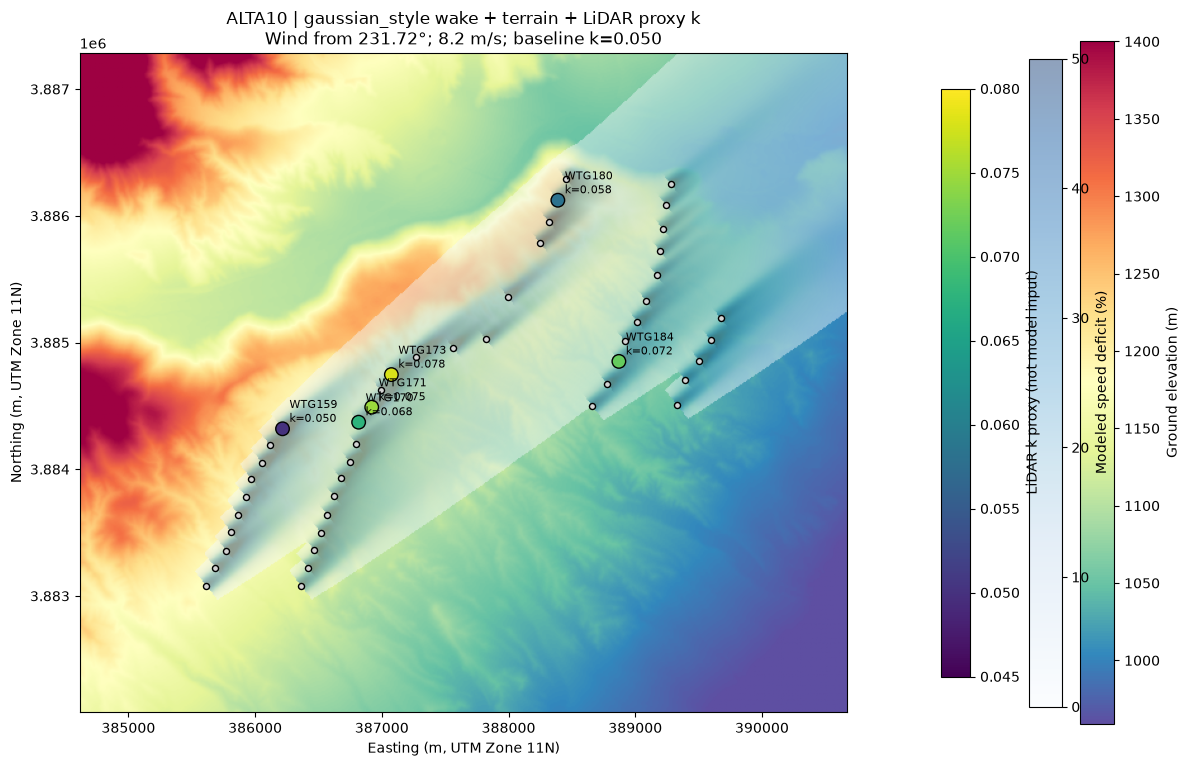

In [13]:
def wake_map_grid(model, terrain, X, Y, farm):
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("Wake model must be jensen or gaussian_style")
    theta = np.deg2rad(WIND_FROM_DEG)
    dx, dy = -np.sin(theta), -np.cos(theta)
    ct = candidate_ct(FREE_STREAM_SPEED)
    combined_sq = np.zeros_like(terrain, dtype=float)
    for src in farm.itertuples():
        downstream = (X - src.x) * dx + (Y - src.y) * dy
        crosswind = -(X - src.x) * dy + (Y - src.y) * dx
        positive = np.maximum(downstream, 0)
        vertical = terrain - src.elevation_m  # identical hub heights cancel
        center = (1 - np.sqrt(1 - ct)) / (1 + 2 * BASELINE_K * positive / ROTOR_DIAMETER_M)**2
        radius = ROTOR_DIAMETER_M / 2 + BASELINE_K * positive
        if model == "jensen":
            delta = np.where((downstream > 0) &
                (np.hypot(crosswind, vertical) <= radius), center, 0)
        else:
            gauss = np.exp(-.5 * ((crosswind / radius)**2 + (vertical / radius)**2))
            delta = np.where(downstream > 0, center * gauss, 0)
        delta[~np.isfinite(terrain)] = 0
        combined_sq += delta ** 2
    return np.minimum(1., np.sqrt(combined_sq))


if RUN_TERRAIN_WAKE_MAPS:
    import geopandas as gpd
    import rasterio
    from rasterio.warp import reproject, Resampling
    from rasterio.transform import from_origin

    farm = gpd.GeoDataFrame(
        coords.copy(), geometry=gpd.points_from_xy(coords.Longitude, coords.Latitude),
        crs="EPSG:4326"
    ).to_crs("EPSG:32611")
    farm["x"], farm["y"] = farm.geometry.x, farm.geometry.y
    dem_path = find_input("elevation.tif")
    x0, y0, x1, y1 = farm.total_bounds
    x0 -= GRID_PADDING_M; y0 -= GRID_PADDING_M
    x1 += GRID_PADDING_M; y1 += GRID_PADDING_M
    nx = int(np.ceil((x1 - x0) / GRID_RESOLUTION_M))
    ny = int(np.ceil((y1 - y0) / GRID_RESOLUTION_M))
    transform = from_origin(x0, y1, GRID_RESOLUTION_M, GRID_RESOLUTION_M)
    terrain = np.full((ny, nx), np.nan, np.float32)
    with rasterio.open(dem_path) as dem:
        reproject(source=rasterio.band(dem, 1), destination=terrain,
                  src_transform=dem.transform, src_crs=dem.crs,
                  src_nodata=dem.nodata, dst_transform=transform,
                  dst_crs="EPSG:32611", dst_nodata=np.nan,
                  resampling=Resampling.bilinear)
        pts = farm.to_crs(dem.crs)
        samples = list(dem.sample([(p.x, p.y) for p in pts.geometry], masked=True))
        farm["elevation_m"] = [np.nan if np.ma.is_masked(s[0]) else float(s[0])
                               for s in samples]
    if not np.isfinite(terrain).any() or farm.elevation_m.isna().any():
        raise ValueError("DEM not valid over full farm; check data extent and CRS")
    xvec = x0 + (np.arange(nx) + .5) * GRID_RESOLUTION_M
    yvec = y1 - (np.arange(ny) + .5) * GRID_RESOLUTION_M
    X, Y = np.meshgrid(xvec, yvec)
    extent = (x0, x1, y0, y1)
    k_locations = farm.merge(ti_summary[["turbine", "median_k_proxy"]],
                             on="turbine", how="inner", validate="one_to_one")
    print(f"Terrain/wake scenario: {len(farm)} sites, {len(k_locations)} with LiDAR, grid {nx}x{ny}")

    def plot_scenario(model):
        deficit = wake_map_grid(model, terrain, X, Y, farm)
        fig, ax = plt.subplots(figsize=(12, 8))
        back = ax.imshow(terrain, extent=extent, origin="upper", cmap="Spectral_r",
                         vmin=np.nanpercentile(terrain, 2),
                         vmax=np.nanpercentile(terrain, 98), zorder=1)
        wake = np.ma.masked_where((deficit < .01) | ~np.isfinite(terrain), deficit * 100)
        overlay = ax.imshow(wake, extent=extent, origin="upper", cmap="Blues",
                            vmin=0, vmax=50, alpha=.45, zorder=2)
        ax.scatter(farm.x, farm.y, s=19, c="lightgray", edgecolors="black", zorder=4)
        pts = ax.scatter(k_locations.x, k_locations.y, c=k_locations.median_k_proxy,
                         cmap="viridis", vmin=.045, vmax=.08, s=95,
                         edgecolors="black", zorder=6)
        for row in k_locations.itertuples():
            ax.annotate(f"{row.turbine}\nk={row.median_k_proxy:.3f}",
                        (row.x, row.y), xytext=(5, 5), textcoords="offset points",
                        fontsize=8, zorder=7)
        fig.colorbar(back, ax=ax, fraction=.033, pad=.018).set_label("Ground elevation (m)")
        fig.colorbar(overlay, ax=ax, fraction=.033, pad=.06).set_label("Modeled speed deficit (%)")
        fig.colorbar(pts, ax=ax, fraction=.033, pad=.105).set_label("LiDAR k proxy (not model input)")
        ax.set(xlabel="Easting (m, UTM Zone 11N)", ylabel="Northing (m, UTM Zone 11N)",
               title=f"ALTA10 | {model} wake + terrain + LiDAR proxy k\n"
                     f"Wind from {WIND_FROM_DEG:.2f}°; {FREE_STREAM_SPEED:.1f} m/s; baseline k={BASELINE_K:.3f}")
        ax.set_aspect("equal")
        finish_plot(fig, f"09_terrain_{model}_and_k")
        return deficit

    jensen_deficit = plot_scenario("jensen")
    gaussian_deficit = plot_scenario("gaussian_style")
else:
    print("Terrain / wake map generation disabled; change RUN_TERRAIN_WAKE_MAPS=True to enable.")


### Hub-center turbine wake predictions (separate from grid visualization)

Same source/target layout and quadratic combination as notebook 05. All
potential upstream sources have the same candidate Ct at simulated inflow.
A predicted 0% at a hub **does not** prove no partial rotor wake overlap.

ILLUSTRATIVE HUB-CENTER WAKE PREDICTIONS


,turbine,model,predicted_deficit_pct,predicted_hub_speed_ms,contributing_sources
23,WTG174,jensen,45.336,4.482,6
70,WTG174,gaussian_style,44.199,4.576,12
22,WTG173,jensen,42.901,4.682,5
20,WTG171,jensen,41.692,4.781,4
7,WTG157,jensen,38.917,5.009,1
2,WTG152,jensen,38.560,5.038,1
9,WTG159,jensen,38.049,5.080,1
35,WTG186,jensen,37.290,5.142,4
67,WTG171,gaussian_style,36.907,5.174,9
44,WTG195,jensen,36.584,5.200,1


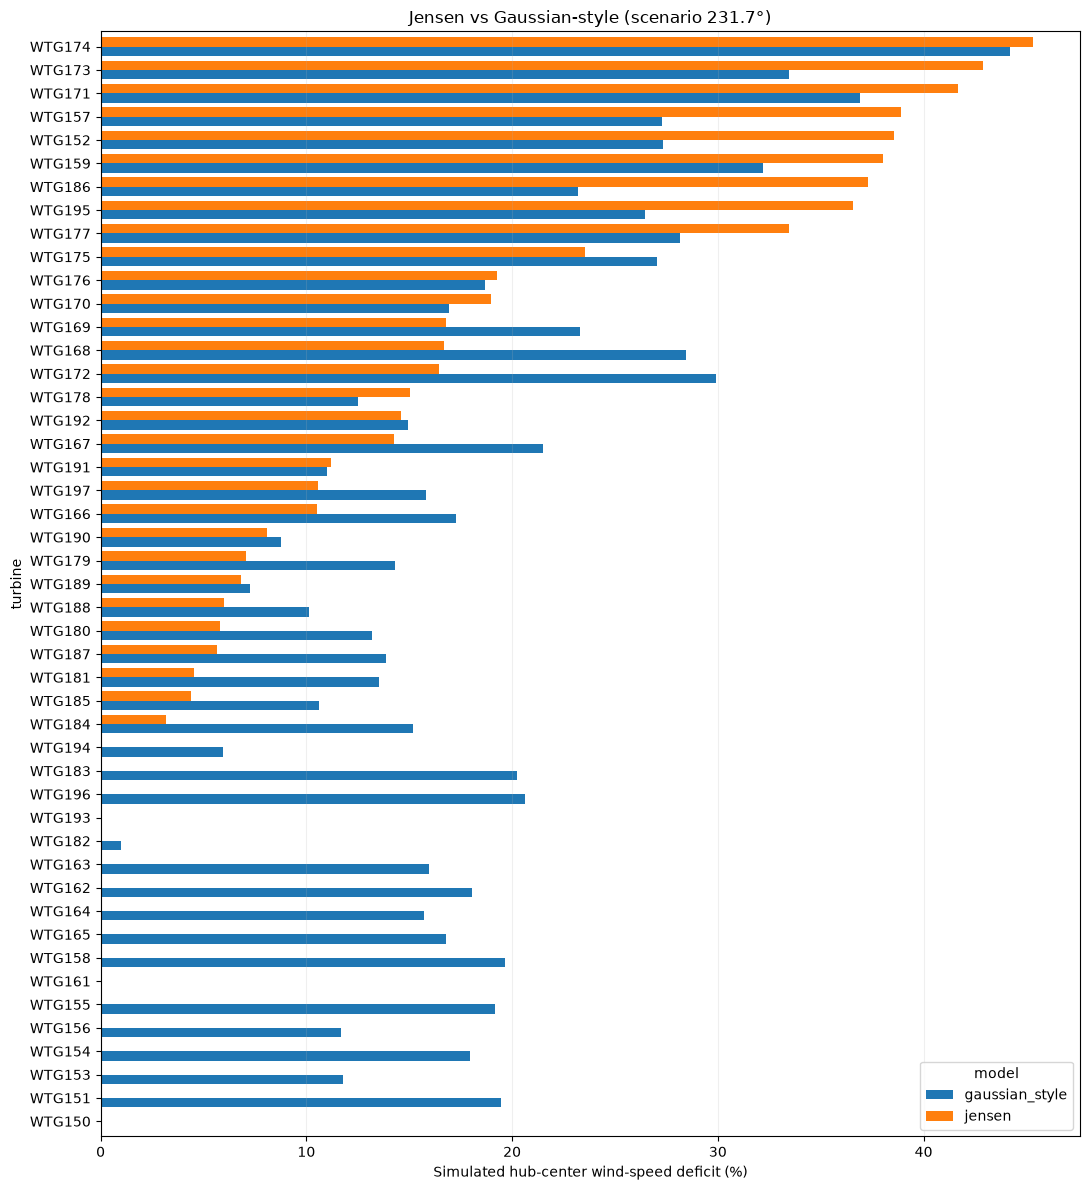

In [14]:
if RUN_TERRAIN_WAKE_MAPS:
    def hub_predictions(model):
        theta = np.deg2rad(WIND_FROM_DEG)
        dx, dy = -np.sin(theta), -np.cos(theta)
        ct = candidate_ct(FREE_STREAM_SPEED)
        rows = []
        for target in farm.itertuples():
            sq, contributors = 0., 0
            for source in farm.itertuples():
                if target.turbine == source.turbine:
                    continue
                ex, ey = target.x - source.x, target.y - source.y
                along = ex * dx + ey * dy
                if along <= 0 or ct <= 0:
                    continue
                across = -ex * dy + ey * dx
                vert = target.elevation_m - source.elevation_m
                radius = ROTOR_DIAMETER_M / 2 + BASELINE_K * along
                center = (1 - np.sqrt(1 - ct)) / (1 + 2 * BASELINE_K * along / ROTOR_DIAMETER_M)**2
                if model == "jensen":
                    hit = np.hypot(across, vert) <= radius
                    delta = center if hit else 0.
                    contributors += int(hit)
                else:
                    delta = center * np.exp(-.5 * ((across / radius)**2 + (vert / radius)**2))
                    contributors += int(delta >= .01)
                sq += delta**2
            loss = min(np.sqrt(sq), 1.)
            rows.append({"turbine": target.turbine, "model": model,
                         "predicted_deficit_pct": 100 * loss,
                         "predicted_hub_speed_ms": FREE_STREAM_SPEED * (1 - loss),
                         "contributing_sources": contributors})
        return pd.DataFrame(rows)

    wake_predictions = pd.concat([
        hub_predictions("jensen"), hub_predictions("gaussian_style")
    ], ignore_index=True)
    print("ILLUSTRATIVE HUB-CENTER WAKE PREDICTIONS")
    display(wake_predictions.sort_values("predicted_deficit_pct", ascending=False).head(15).round(3))
    save_table(wake_predictions, "09_hub_center_wake_predictions")
    wake_pivot = wake_predictions.pivot(index="turbine", columns="model", values="predicted_deficit_pct")
    fig, ax = plt.subplots(figsize=(11, 12))
    wake_pivot.sort_values("jensen").plot.barh(ax=ax, width=.8)
    ax.set(xlabel="Simulated hub-center wind-speed deficit (%)",
           title=f"Jensen vs Gaussian-style (scenario {WIND_FROM_DEG:.1f}°)")
    ax.grid(axis="x", alpha=.2)
    finish_plot(fig, "09_hub_center_model_comparison")


## 11. Research synthesis — what is and is not established

**Supported by the supplied data and exploratory filters**
- WTG159's matched SCADA wind speed was often higher than LiDAR speed;
  a typical positive offset persisted after preliminary screening.
- WTG159 had highly concentrated anomalous-low LiDAR periods, especially
  May 16–17 and June 8. Both line-of-sight beams changed with the low-speed
  reconstruction; low readings are not explained solely by missing rows.
- The other five LiDAR-equipped sites rarely met that particular high-Sensor
  / low-LiDAR condition on June 8.
- TI-derived local variability differs across all six sites, including
  matched time and broad speed range. This does NOT establish wake causality.
- Power-curve residuals depend on sensor source, site and speed bin.

**Still unverified**
- Whether SCADA `wind_speed` is a true independent anemometer speed
- Whether `sensor1_wsp` / `wtg1_wsp` are independent of SCADA and each other
- LiDAR mount, beam heights/ranges, reconstruction algorithms, modes 0/1
- LiDAR confidence / quality flags (nonmissing != reliable)
- Geographic reference and yaw conventions across `*_phi` and SCADA fields
- Whether LiDAR/SCADA stamps designate the same averaging window
- Power-curve source, valid density correction and operational status filters
- OEM Ct curve, ambient TI, and calibrated wake/terrain-flow coefficients

**Do not conclude:** "WTG159 anemometer is biased"; "LiDAR is broken";
"WTG173 has higher Jensen k because of upstream wakes"; or "power-curve
agreement proves SCADA sensor calibration" from these screens alone.

## 12. Next research phase — actionable order of operations

**A. Sponsor / data definitions (highest priority):**
1. Obtain LiDAR mode meanings, LOS beam geometry, calibration and CNR/SNR or
   vendor QC fields, including May 16–17 and June 8 service/event logs.
2. Confirm actual wind measurement origin for SCADA `wind_speed`,
   `sensor1_wsp`, `wtg1_wsp`, and each LiDAR reconstruction.
3. Confirm timestamp UTC and interval label start/end. Resolve directional
   geographic/yaw reference and any turbine-specific zero offsets.
4. Obtain SCADA fault, curtailment, status, shutdown, and alarm information.

**B. Re-run sensor comparison after verification:**
5. Implement certified LiDAR QC (not solely >20/<8 anomaly flags) and
   generate valid/flagged coverage and source-level uncertainty summaries.
6. Compare paired instrument residuals by turbine, time, wind-speed bin,
   direction (once validated), mode, turbulence and operating state.
7. Estimate interval/day block-bootstrap uncertainty (not independent
   1-second samples) and hold out turbines/dates for final validation.

**C. Advance wake / power physics:**
8. Obtain official GE Ct, power curve provenance, and density normalization;
   validate power against independent, unwaked, normal-operation periods.
9. Apply published Gaussian wake formulation if appropriate (our present
   `gaussian_style` is NOT one), and compare with Jensen sensitivity k values.
10. Use validated ambient inflow wind direction and a terrain-flow approach
    when possible; pair predicted wake exposure with *same-time* observed TI.
11. Evaluate sensor bias detection based on multi-sensor evidence, comparing
    against documented instrument service/maintenance outcomes.

**Deliverables to prepare next:** validated data dictionary; QC report by
turbine; signed/absolute error vs speed and direction; uncertainty bands;
same-time wake-exposure/TI comparisons; research methods and limitations.

In [15]:
print("\n" + "=" * 65)
print("06 RESEARCH SYNTHESIS FINISHED")
print(f"Six LiDAR turbines: {len(LIDAR_TURBINES)}")
print(f"Ten-minute LiDAR slots: {len(lidar_intervals):,}")
print(f"Matched 10-minute LiDAR / SCADA records: {len(all_matched):,}")
print(f"Power-curve filtered records: {len(power_data):,}")
print("Interpretation: exploratory diagnostics, NOT verified fault classifications")
print(f"Tables and figures: {RESULT_DIR}")



06 RESEARCH SYNTHESIS FINISHED
Six LiDAR turbines: 6
Ten-minute LiDAR slots: 115,488
Matched 10-minute LiDAR / SCADA records: 88,934
Power-curve filtered records: 48,694
Interpretation: exploratory diagnostics, NOT verified fault classifications
Tables and figures: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\06_research_synthesis


In [16]:
# ======================================================
# ALTA10 - WIND ROSE ANALYSIS
# STEP 1: INSPECT MET MAST DATA
# ======================================================

from pathlib import Path
import pandas as pd

# Project directory
project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

# Load processed met mast data
metmast_path = (
    project_path / "data" / "processed" / "metmasts_data.parquet"
)

metmasts = pd.read_parquet(metmast_path)

print("MET MAST DATA OVERVIEW")
print("-" * 45)

print("Dataset dimensions:", metmasts.shape)

print("\nCOLUMN NAMES AND DATA TYPES:")
print(metmasts.dtypes.to_string())

print("\nFIRST THREE OBSERVATIONS:")
display(metmasts.head(3).T)

print("\nPOSSIBLE WIND SPEED / DIRECTION FIELDS:")

keywords = [
    "wind", "speed", "direction",
    "wsp", "wdir", "dir", "mast"
]

candidate_columns = [
    col for col in metmasts.columns
    if any(word in col.lower() for word in keywords)
]

print(candidate_columns)

MET MAST DATA OVERVIEW
---------------------------------------------
Dataset dimensions: (39306, 14)

COLUMN NAMES AND DATA TYPES:
utc                     datetime64[ns]
mm_wind_speed_1                float64
mm_wind_speed_2                float64
mm_wind_speed_3                float64
mm_wind_speed_hh               float64
mm_wind_direction_1            float64
mm_wind_direction_2            float64
mm_wind_direction_3            float64
mm_wind_direction_hh           float64
mm_pressure_bar_1              float64
mm_pressure_bar_2              float64
mm_rel_humidity_1              float64
mm_rel_humidity_2              float64
mm_temp_amb                    float64

FIRST THREE OBSERVATIONS:


,0,1,2
utc,2026-01-01 08:00:00,2026-01-01 08:10:00,2026-01-01 08:20:00
mm_wind_speed_1,NaN,NaN,NaN
mm_wind_speed_2,6.788382,6.259118,6.533529
mm_wind_speed_3,5.399412,5.094412,5.542794
mm_wind_speed_hh,0.700615,0.69746,0.703226
mm_wind_direction_1,71.916912,67.399852,72.914559
mm_wind_direction_2,54.93603,51.146323,57.126323
mm_wind_direction_3,67.719853,64.681471,70.034118
mm_wind_direction_hh,47.655736,43.452206,51.133089
mm_pressure_bar_1,NaN,NaN,NaN



POSSIBLE WIND SPEED / DIRECTION FIELDS:
['mm_wind_speed_1', 'mm_wind_speed_2', 'mm_wind_speed_3', 'mm_wind_speed_hh', 'mm_wind_direction_1', 'mm_wind_direction_2', 'mm_wind_direction_3', 'mm_wind_direction_hh']


In [17]:
# =====================================================
# ALTA10 - WIND ROSE
# STEP 2: MET MAST DATA QUALITY COMPARISON
# =====================================================

import numpy as np
import pandas as pd

results = []

for sensor in ["1", "2", "3", "hh"]:

    speed_col = f"mm_wind_speed_{sensor}"
    direction_col = f"mm_wind_direction_{sensor}"

    speed = pd.to_numeric(
        metmasts[speed_col], errors="coerce"
    )

    direction = pd.to_numeric(
        metmasts[direction_col], errors="coerce"
    )

    # Plausibility screening for exploratory analysis
    valid = (
        speed.between(0, 40) &
        direction.between(0, 360, inclusive="left")
    )

    results.append({
        "sensor": sensor,
        "total_records": len(metmasts),
        "valid_pairs": valid.sum(),
        "coverage_pct": valid.mean() * 100,
        "mean_speed": speed[valid].mean(),
        "median_speed": speed[valid].median(),
        "max_speed": speed[valid].max()
    })

mast_quality = pd.DataFrame(results)

print("ALTA10 - MET MAST DATA QUALITY")
display(mast_quality.round(2))

# Check the available observation period
timestamps = pd.to_datetime(
    metmasts["utc"], errors="coerce", utc=True
)

print("\nDATASET PERIOD")
print("Start:", timestamps.min())
print("End:", timestamps.max())
print("Total records:", len(metmasts))

ALTA10 - MET MAST DATA QUALITY


,sensor,total_records,valid_pairs,coverage_pct,mean_speed,median_speed,max_speed
0,1,39306,22,0.06,0.00,0.00,0.00
1,2,39306,38134,97.02,9.51,8.13,31.75
2,3,39306,38368,97.61,9.49,9.12,27.25
3,hh,39306,38367,97.61,9.12,8.70,29.45



DATASET PERIOD
Start: 2026-01-01 08:00:00+00:00
End: 2026-10-01 06:50:00+00:00
Total records: 39306


Valid wind observations: 38134


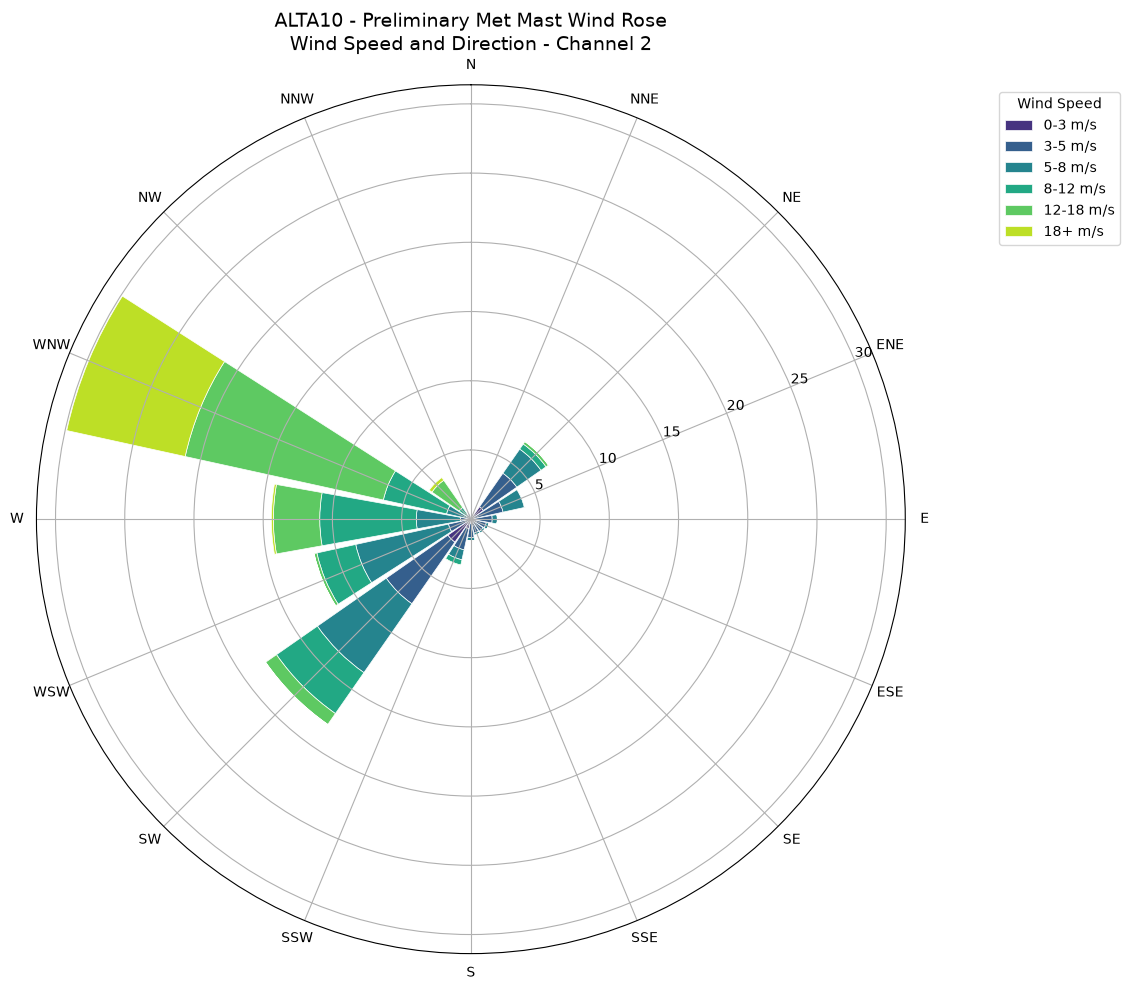


MOST FREQUENT WIND DIRECTIONS


,direction,frequency_pct
13,WNW,29.88
10,SW,18.09
12,W,14.41
11,WSW,11.60
2,NE,6.85
3,ENE,4.02
14,NW,3.66
9,SSW,3.45


In [18]:
# =====================================================
# ALTA10 - WIND ROSE
# STEP 3: EXPLORATORY MET MAST WIND ROSE
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select our provisional measurement pair
speed_col = "mm_wind_speed_2"
direction_col = "mm_wind_direction_2"

rose_data = metmasts[[speed_col, direction_col]].copy()

rose_data.columns = ["wind_speed", "wind_direction"]

rose_data = rose_data.apply(
    pd.to_numeric, errors="coerce"
)

# Preliminary data-quality filter
rose_data = rose_data[
    rose_data["wind_speed"].between(0, 40) &
    rose_data["wind_direction"].between(
        0, 360, inclusive="left"
    )
].copy()

print("Valid wind observations:", len(rose_data))

if rose_data.empty:
    raise ValueError("No valid wind observations found.")

# ---------------------------------
# Direction and speed bins
# ---------------------------------

n_sectors = 16
sector_width = 360 / n_sectors

speed_bins = [0, 3, 5, 8, 12, 18, np.inf]

speed_labels = [
    "0-3 m/s",
    "3-5 m/s",
    "5-8 m/s",
    "8-12 m/s",
    "12-18 m/s",
    "18+ m/s"
]

# Assign each observation to a compass sector
directions = rose_data["wind_direction"].to_numpy()
speeds = rose_data["wind_speed"].to_numpy()

direction_idx = (
    np.floor((directions + sector_width / 2)
             / sector_width).astype(int) % n_sectors
)

speed_idx = np.searchsorted(
    speed_bins[1:-1],
    speeds,
    side="right"
)

# Count observations
counts = np.zeros(
    (n_sectors, len(speed_labels))
)

np.add.at(
    counts,
    (direction_idx, speed_idx),
    1
)

# Convert to percentages of all valid observations
frequencies = counts / counts.sum() * 100

# ---------------------------------
# Create polar wind rose
# ---------------------------------

fig, ax = plt.subplots(
    figsize=(11, 10),
    subplot_kw={"projection": "polar"}
)

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

theta = np.deg2rad(
    np.arange(n_sectors) * sector_width
)

width = np.deg2rad(sector_width * 0.90)

bottom = np.zeros(n_sectors)

colors = plt.cm.viridis(
    np.linspace(0.15, 0.90, len(speed_labels))
)

for i, label in enumerate(speed_labels):

    values = frequencies[:, i]

    ax.bar(
        theta,
        values,
        width=width,
        bottom=bottom,
        color=colors[i],
        label=label,
        edgecolor="white",
        linewidth=0.5
    )

    bottom += values

compass_labels = [
    "N", "NNE", "NE", "ENE",
    "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW",
    "W", "WNW", "NW", "NNW"
]

ax.set_xticks(theta)
ax.set_xticklabels(compass_labels)

ax.set_title(
    "ALTA10 - Preliminary Met Mast Wind Rose\n"
    "Wind Speed and Direction - Channel 2",
    pad=25,
    fontsize=14
)

ax.set_rlabel_position(67.5)

ax.legend(
    title="Wind Speed",
    loc="upper left",
    bbox_to_anchor=(1.10, 1.0)
)

plt.tight_layout()
plt.show()

# ---------------------------------
# Summary of wind directions
# ---------------------------------

direction_summary = pd.DataFrame({
    "direction": compass_labels,
    "frequency_pct": frequencies.sum(axis=1)
}).sort_values("frequency_pct", ascending=False)

print("\nMOST FREQUENT WIND DIRECTIONS")
display(direction_summary.head(8).round(2))

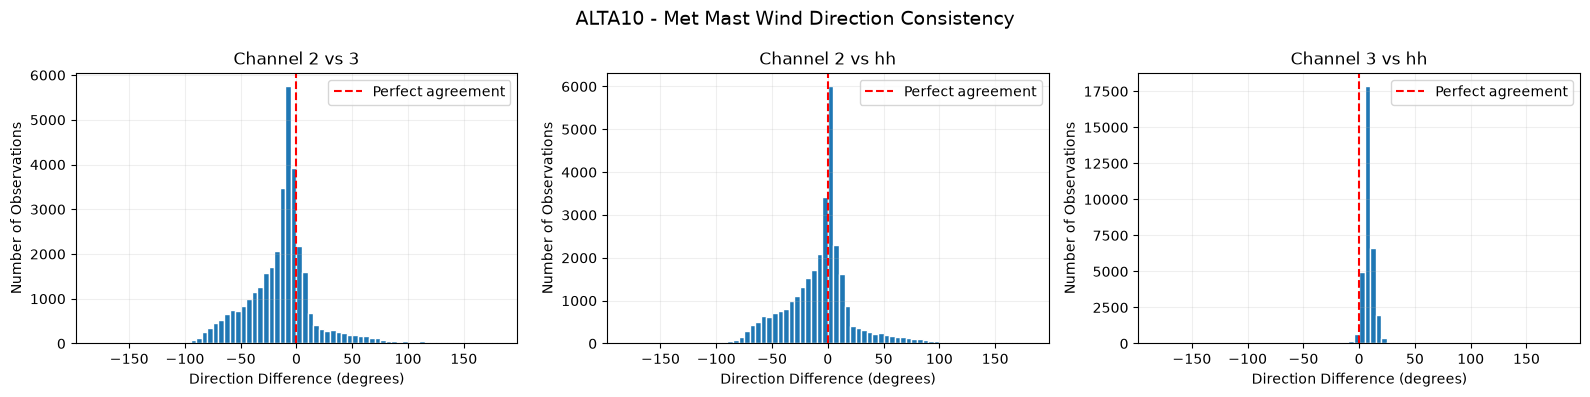

MET MAST DIRECTION COMPARISON


,sensors,observations,median_signed_difference_deg,median_absolute_difference_deg,90th_pct_absolute_difference_deg,agreement_within_22_5_deg_pct,wind_speed_correlation
0,2 vs 3,35007,-9.76,14.81,62.92,60.36,0.84
1,2 vs hh,31813,-1.85,13.07,59.43,64.40,0.84
2,3 vs hh,33132,7.81,7.86,14.22,98.55,0.98


In [19]:
# =====================================================
# ALTA10 - WIND ROSE
# STEP 4: COMPARE MET MAST DIRECTION SENSORS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sensor_pairs = [
    ("2", "3"),
    ("2", "hh"),
    ("3", "hh")
]

results = []

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4),
    sharex=True
)

for ax, (sensor_a, sensor_b) in zip(
    axes, sensor_pairs
):

    dir_a = pd.to_numeric(
        metmasts[f"mm_wind_direction_{sensor_a}"],
        errors="coerce"
    )

    dir_b = pd.to_numeric(
        metmasts[f"mm_wind_direction_{sensor_b}"],
        errors="coerce"
    )

    speed_a = pd.to_numeric(
        metmasts[f"mm_wind_speed_{sensor_a}"],
        errors="coerce"
    )

    speed_b = pd.to_numeric(
        metmasts[f"mm_wind_speed_{sensor_b}"],
        errors="coerce"
    )

    # Compare only reasonable operating conditions.
    # Avoid low wind speeds where direction can be noisy.
    valid = (
        dir_a.between(0, 360, inclusive="left") &
        dir_b.between(0, 360, inclusive="left") &
        speed_a.between(3, 40) &
        speed_b.between(3, 40)
    )

    # Circular difference handles crossing 0 / 360 degrees
    direction_difference = (
        (dir_a[valid] - dir_b[valid] + 180)
        % 360
    ) - 180

    abs_difference = direction_difference.abs()

    results.append({
        "sensors": f"{sensor_a} vs {sensor_b}",
        "observations": valid.sum(),
        "median_signed_difference_deg":
            direction_difference.median(),
        "median_absolute_difference_deg":
            abs_difference.median(),
        "90th_pct_absolute_difference_deg":
            abs_difference.quantile(0.90),
        "agreement_within_22_5_deg_pct":
            (abs_difference <= 22.5).mean() * 100,
        "wind_speed_correlation":
            speed_a[valid].corr(speed_b[valid])
    })

    ax.hist(
        direction_difference,
        bins=np.arange(-180, 185, 5),
        edgecolor="white"
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--",
        label="Perfect agreement"
    )

    ax.set_title(
        f"Channel {sensor_a} vs {sensor_b}"
    )
    ax.set_xlabel(
        "Direction Difference (degrees)"
    )
    ax.set_ylabel("Number of Observations")
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle(
    "ALTA10 - Met Mast Wind Direction Consistency",
    fontsize=14
)

plt.tight_layout()
plt.show()

mast_direction_comparison = pd.DataFrame(results)

print("MET MAST DIRECTION COMPARISON")
display(mast_direction_comparison.round(2))

Matched valid observations: 31797


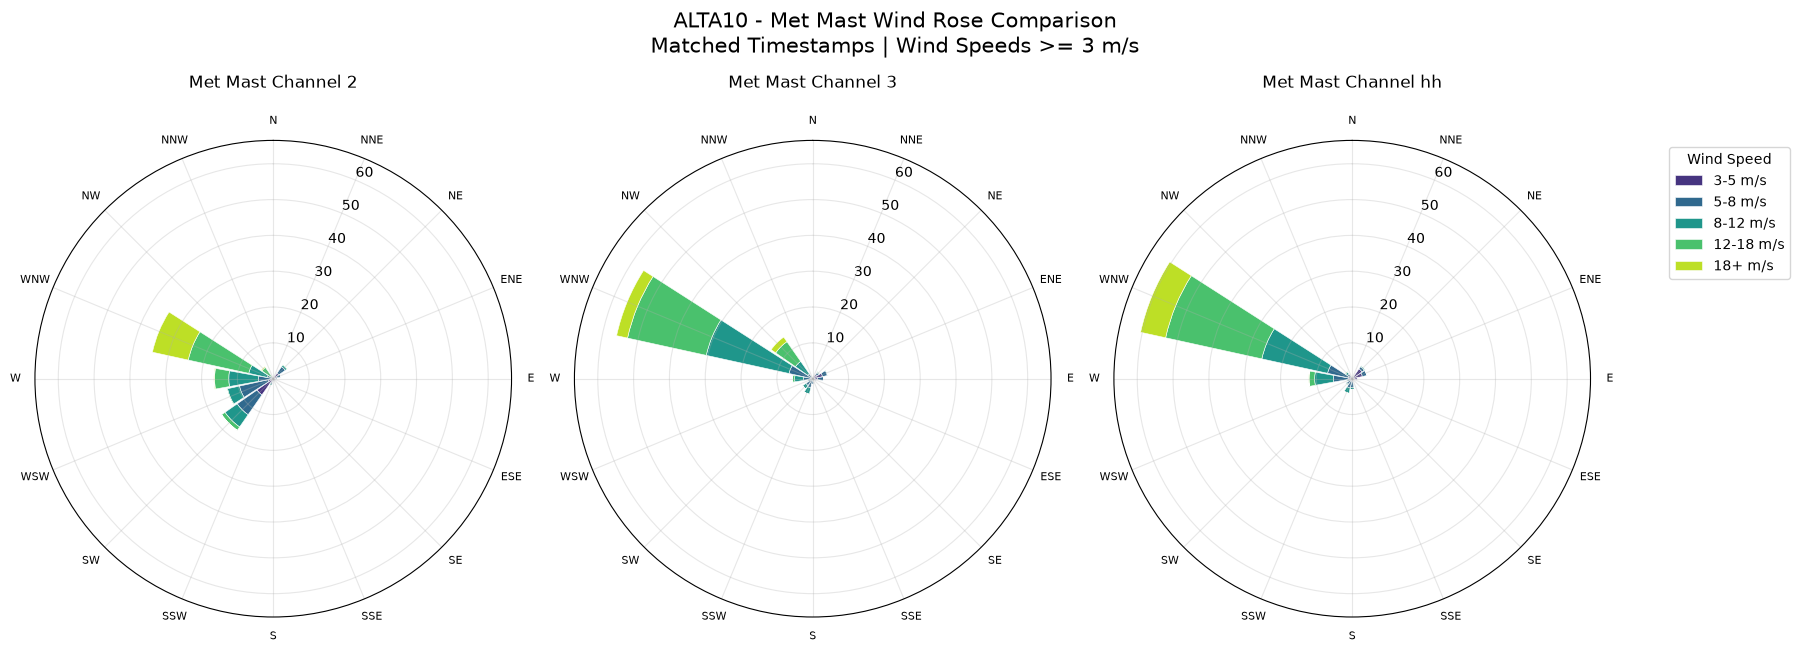


DIRECTION FREQUENCY COMPARISON


,direction,channel_2_pct,channel_3_pct,channel_hh_pct
13,WNW,34.53,56.05,60.47
14,NW,4.10,14.15,2.54
12,W,16.56,5.62,12.12
9,SSW,2.01,4.45,4.22
3,ENE,2.21,4.40,4.26
10,SW,17.58,3.45,2.24
4,E,1.13,3.01,1.64
2,NE,4.90,2.52,4.50
8,S,0.96,1.62,3.05
11,WSW,13.33,1.55,1.59


In [20]:
# =====================================================
# ALTA10 - WIND ROSE
# STEP 5: COMPARE THREE MET MAST WIND ROSES
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sensors = ["2", "3", "hh"]

# ----------------------------------------------
# 1. SELECT MATCHED VALID OBSERVATIONS
# ----------------------------------------------

mast_compare = metmasts.copy()

valid = pd.Series(True, index=mast_compare.index)

for sensor in sensors:

    wsp = f"mm_wind_speed_{sensor}"
    wdir = f"mm_wind_direction_{sensor}"

    mast_compare[wsp] = pd.to_numeric(
        mast_compare[wsp], errors="coerce"
    )

    mast_compare[wdir] = pd.to_numeric(
        mast_compare[wdir], errors="coerce"
    )

    valid &= (
        mast_compare[wsp].between(3, 40) &
        mast_compare[wdir].between(
            0, 360, inclusive="left"
        )
    )

mast_compare = mast_compare.loc[valid].copy()

print("Matched valid observations:", len(mast_compare))

if mast_compare.empty:
    raise ValueError("No valid common observations.")

# ----------------------------------------------
# 2. WIND ROSE CONFIGURATION
# ----------------------------------------------

n_sectors = 16
sector_width = 360 / n_sectors

speed_bins = [3, 5, 8, 12, 18, np.inf]

speed_labels = [
    "3-5 m/s",
    "5-8 m/s",
    "8-12 m/s",
    "12-18 m/s",
    "18+ m/s"
]

compass_labels = [
    "N", "NNE", "NE", "ENE",
    "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW",
    "W", "WNW", "NW", "NNW"
]

theta = np.deg2rad(
    np.arange(n_sectors) * sector_width
)

colors = plt.cm.viridis(
    np.linspace(0.15, 0.90, len(speed_labels))
)

# ----------------------------------------------
# 3. CALCULATE FREQUENCIES
# ----------------------------------------------

rose_frequencies = {}

for sensor in sensors:

    directions = mast_compare[
        f"mm_wind_direction_{sensor}"
    ].to_numpy()

    speeds = mast_compare[
        f"mm_wind_speed_{sensor}"
    ].to_numpy()

    direction_idx = (
        np.floor(
            (directions + sector_width / 2)
            / sector_width
        ).astype(int) % n_sectors
    )

    speed_idx = np.searchsorted(
        speed_bins[1:-1],
        speeds,
        side="right"
    )

    counts = np.zeros(
        (n_sectors, len(speed_labels))
    )

    np.add.at(
        counts,
        (direction_idx, speed_idx),
        1
    )

    rose_frequencies[sensor] = (
        counts / counts.sum() * 100
    )

# ----------------------------------------------
# 4. THREE WIND ROSES
# ----------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    subplot_kw={"projection": "polar"}
)

for ax, sensor in zip(axes, sensors):

    frequency = rose_frequencies[sensor]

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    bottom = np.zeros(n_sectors)

    for i, label in enumerate(speed_labels):

        ax.bar(
            theta,
            frequency[:, i],
            width=np.deg2rad(sector_width * 0.9),
            bottom=bottom,
            color=colors[i],
            edgecolor="white",
            linewidth=0.4,
            label=label
        )

        bottom += frequency[:, i]

    ax.set_xticks(theta)
    ax.set_xticklabels(
        compass_labels, fontsize=8
    )

    ax.set_title(
        f"Met Mast Channel {sensor}",
        fontsize=12,
        pad=20
    )

    ax.grid(alpha=0.3)

# Shared radial axis scale
maximum_frequency = max(
    rose_frequencies[s].sum(axis=1).max()
    for s in sensors
)

for ax in axes:
    ax.set_ylim(0, maximum_frequency * 1.10)

axes[-1].legend(
    title="Wind Speed",
    loc="upper left",
    bbox_to_anchor=(1.15, 1.0)
)

plt.suptitle(
    "ALTA10 - Met Mast Wind Rose Comparison\n"
    "Matched Timestamps | Wind Speeds >= 3 m/s",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ----------------------------------------------
# 5. COMPARE PREVAILING DIRECTIONS
# ----------------------------------------------

comparison = pd.DataFrame({
    "direction": compass_labels
})

for sensor in sensors:

    comparison[f"channel_{sensor}_pct"] = (
        rose_frequencies[sensor].sum(axis=1)
    )

print("\nDIRECTION FREQUENCY COMPARISON")

display(
    comparison.sort_values(
        "channel_3_pct",
        ascending=False
    ).round(2)
)

MET MAST DIRECTION QUALITY BY SECTOR


,sector,observations,median_abs_2_3,median_abs_3_hh,pct_disagree_2_3,pct_disagree_3_hh
0,NNE,109,7.17,4.80,34.86,4.59
1,NE,802,9.35,6.50,22.57,1.00
2,ENE,1400,22.33,11.53,49.71,1.14
3,E,958,27.75,15.11,56.47,3.13
4,ESE,390,26.86,15.65,55.13,7.95
5,SE,220,56.30,15.64,82.27,11.82
6,SSE,239,51.57,15.11,88.28,10.88
7,S,514,37.20,13.14,96.69,4.47
8,SSW,1415,15.88,12.32,29.47,1.48
9,SW,1098,9.51,10.30,18.03,1.28


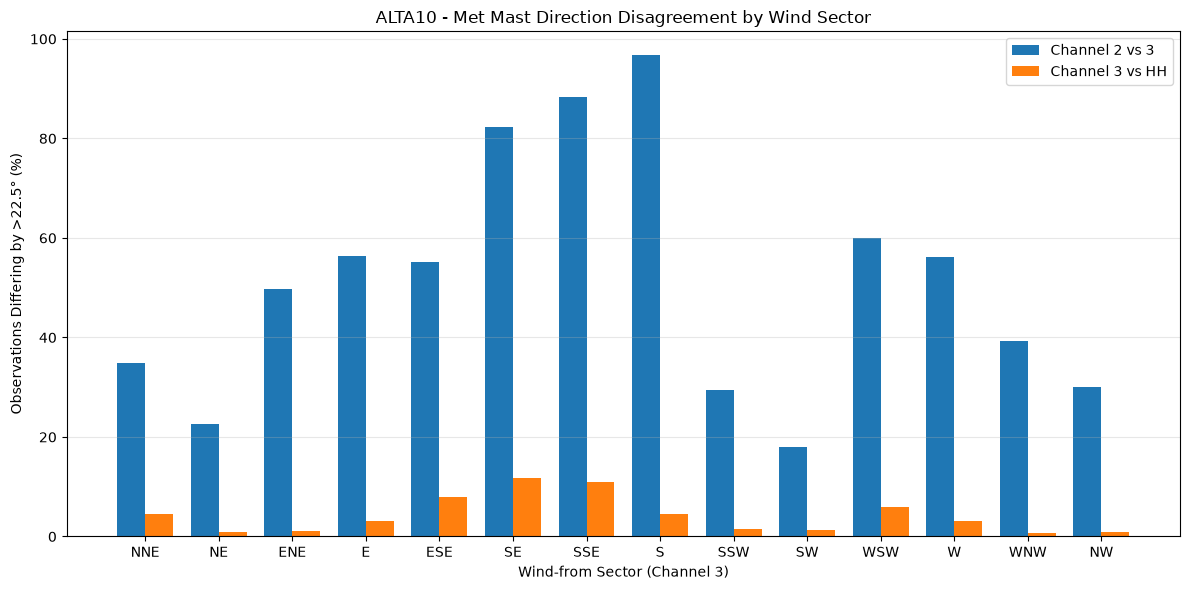

In [21]:
# =====================================================
# ALTA10 - MET MAST DIRECTION QUALITY
# STEP 6: SENSOR DISAGREEMENT BY WIND SECTOR
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the 31,797 common observations
data = mast_compare.copy()

def circular_difference(a, b):
    return (a - b + 180) % 360 - 180

# Compare directional disagreements
data["diff_2_3"] = circular_difference(
    data["mm_wind_direction_2"],
    data["mm_wind_direction_3"]
)

data["diff_3_hh"] = circular_difference(
    data["mm_wind_direction_3"],
    data["mm_wind_direction_hh"]
)

# Use channel 3 as the provisional grouping reference,
# NOT as confirmed true geographic wind direction
sectors = [
    "N", "NNE", "NE", "ENE",
    "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW",
    "W", "WNW", "NW", "NNW"
]

sector_idx = (
    np.floor(
        ((data["mm_wind_direction_3"] + 11.25) % 360)
        / 22.5
    ).astype(int)
)

data["wind_sector"] = pd.Categorical(
    [sectors[i] for i in sector_idx],
    categories=sectors,
    ordered=True
)

# Compute disagreement statistics for each sector
results = []

for sector, group in data.groupby(
    "wind_sector", observed=True
):

    abs_23 = group["diff_2_3"].abs()
    abs_3hh = group["diff_3_hh"].abs()

    results.append({
        "sector": sector,
        "observations": len(group),
        "median_abs_2_3": abs_23.median(),
        "median_abs_3_hh": abs_3hh.median(),
        "pct_disagree_2_3": (abs_23 > 22.5).mean() * 100,
        "pct_disagree_3_hh": (abs_3hh > 22.5).mean() * 100
    })

sector_quality = pd.DataFrame(results)

# Sort in compass order
sector_quality["sector"] = pd.Categorical(
    sector_quality["sector"],
    categories=sectors,
    ordered=True
)

sector_quality = sector_quality.sort_values("sector")

print("MET MAST DIRECTION QUALITY BY SECTOR")
display(sector_quality.round(2))

# ----------------------------------------------
# Plot disagreement frequency by direction
# ----------------------------------------------

plot_data = sector_quality[
    sector_quality["observations"] >= 100
].copy()

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(plot_data))
width = 0.38

ax.bar(
    x - width/2,
    plot_data["pct_disagree_2_3"],
    width,
    label="Channel 2 vs 3"
)

ax.bar(
    x + width/2,
    plot_data["pct_disagree_3_hh"],
    width,
    label="Channel 3 vs HH"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data["sector"])

ax.set_xlabel("Wind-from Sector (Channel 3)")
ax.set_ylabel("Observations Differing by >22.5° (%)")

ax.set_title(
    "ALTA10 - Met Mast Direction Disagreement "
    "by Wind Sector"
)

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Directional simulations complete!
Total results: 864


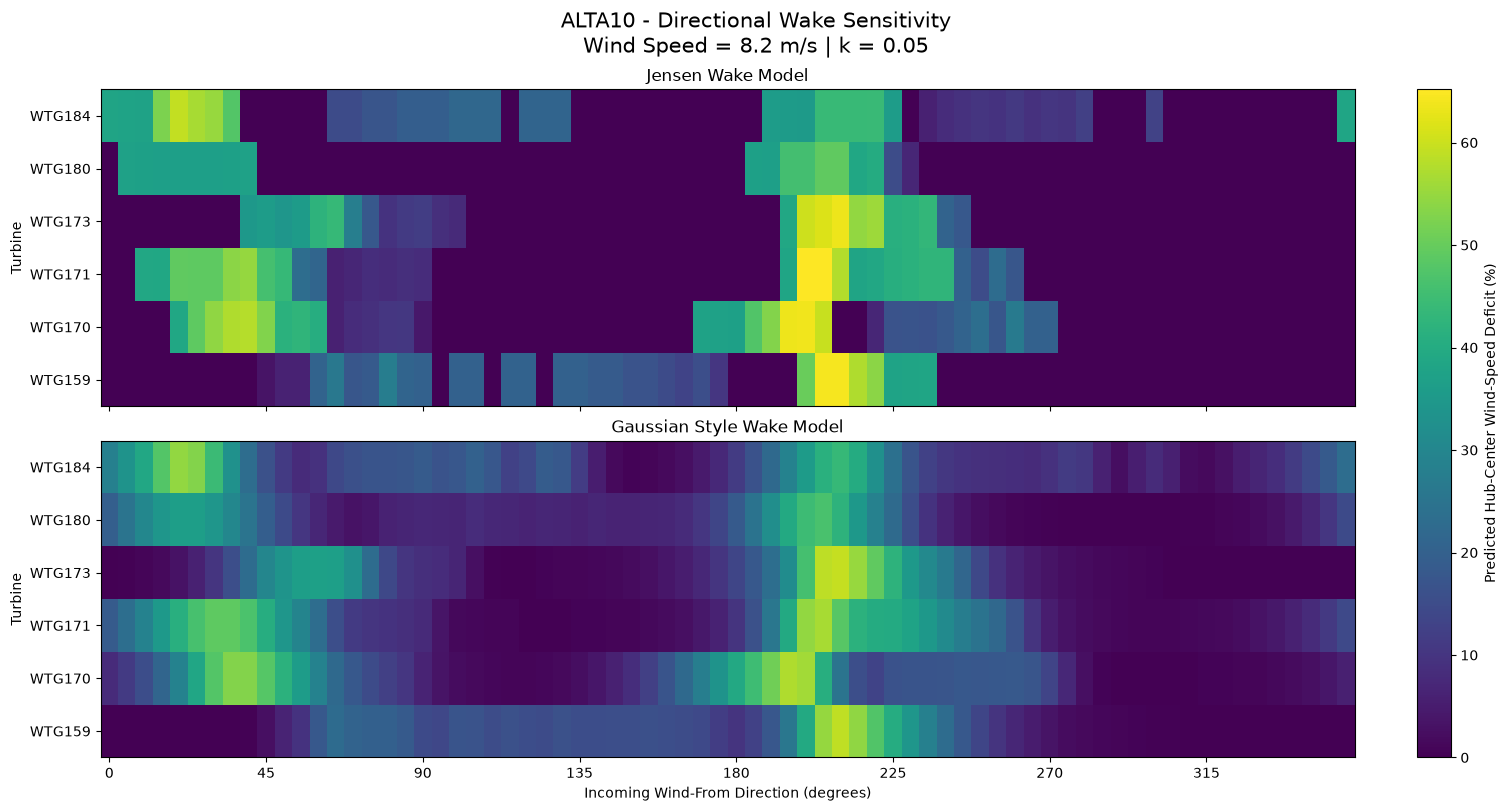


STRONGEST MODELED WAKE DIRECTIONS


,model,turbine,wind_from_deg,predicted_deficit_pct
510,gaussian_style,WTG159,210,58.90
475,gaussian_style,WTG170,195,57.44
500,gaussian_style,WTG171,205,56.68
513,gaussian_style,WTG173,210,59.41
502,gaussian_style,WTG180,205,46.44
59,gaussian_style,WTG184,20,54.53
492,jensen,WTG159,205,64.41
481,jensen,WTG170,200,63.68
482,jensen,WTG171,200,65.19
507,jensen,WTG173,210,63.46


In [22]:
# ======================================================
# ALTA10 - DIRECTIONAL WAKE SENSITIVITY
# 72 DIRECTIONS | SIX LIDAR TURBINES
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check that Part 6's existing model is available
if "hub_predictions" not in globals():
    raise RuntimeError(
        "Run the Part 6 hub-center wake prediction "
        "section before this cell."
    )

# 0, 5, 10, ..., 355 degrees
wind_directions = np.arange(0, 360, 5)

models = ["jensen", "gaussian_style"]
results = []

# Preserve original illustrative wind direction
original_direction = WIND_FROM_DEG

try:
    for direction in wind_directions:

        WIND_FROM_DEG = float(direction)

        for model in models:

            prediction = hub_predictions(model)

            prediction = prediction[
                prediction["turbine"].isin(
                    LIDAR_TURBINES
                )
            ].copy()

            prediction["wind_from_deg"] = direction

            results.append(prediction)

finally:
    WIND_FROM_DEG = original_direction

directional_wakes = pd.concat(
    results, ignore_index=True
)

print("Directional simulations complete!")
print("Total results:", len(directional_wakes))

# ----------------------------------------------
# Create two comparable heatmaps
# ----------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 8),
    sharex=True,
    constrained_layout=True
)

max_deficit = max(
    1,
    directional_wakes["predicted_deficit_pct"].max()
)

for ax, model in zip(axes, models):

    subset = directional_wakes[
        directional_wakes["model"] == model
    ]

    heatmap = subset.pivot(
        index="turbine",
        columns="wind_from_deg",
        values="predicted_deficit_pct"
    ).reindex(
        index=LIDAR_TURBINES,
        columns=wind_directions
    )

    im = ax.imshow(
        heatmap.to_numpy(),
        aspect="auto",
        origin="lower",
        vmin=0,
        vmax=max_deficit,
        cmap="viridis"
    )

    ax.set_yticks(np.arange(len(LIDAR_TURBINES)))
    ax.set_yticklabels(LIDAR_TURBINES)

    ax.set_title(
        f"{model.replace('_', ' ').title()} Wake Model"
    )

    ax.set_ylabel("Turbine")

axes[-1].set_xticks(
    np.arange(0, len(wind_directions), 9)
)

axes[-1].set_xticklabels(
    wind_directions[::9]
)

axes[-1].set_xlabel(
    "Incoming Wind-From Direction (degrees)"
)

fig.colorbar(
    im,
    ax=axes,
    label="Predicted Hub-Center Wind-Speed Deficit (%)"
)

fig.suptitle(
    "ALTA10 - Directional Wake Sensitivity\n"
    f"Wind Speed = {FREE_STREAM_SPEED} m/s | "
    f"k = {BASELINE_K}",
    fontsize=15
)

plt.show()

# ----------------------------------------------
# Strongest wake direction per turbine
# ----------------------------------------------

peak_rows = directional_wakes.groupby(
    ["model", "turbine"]
)["predicted_deficit_pct"].idxmax()

peak_wakes = directional_wakes.loc[
    peak_rows,
    [
        "model",
        "turbine",
        "wind_from_deg",
        "predicted_deficit_pct"
    ]
].sort_values(["model", "turbine"])

print("\nSTRONGEST MODELED WAKE DIRECTIONS")
display(peak_wakes.round(2))

ALTA10 - WEIGHTED WAKE EXPOSURE


,reference,model,turbine,weighted_deficit_pct,directional_exposure_pct
0,Channel 3,gaussian_style,WTG159,6.48,20.23
1,Channel 3,gaussian_style,WTG170,6.54,22.37
2,Channel 3,gaussian_style,WTG171,7.26,17.73
3,Channel 3,gaussian_style,WTG173,7.49,19.07
4,Channel 3,gaussian_style,WTG180,4.48,12.31
5,Channel 3,gaussian_style,WTG184,9.42,23.99
6,Channel 3,jensen,WTG159,5.76,16.35
7,Channel 3,jensen,WTG170,6.07,15.88
8,Channel 3,jensen,WTG171,6.20,13.80
9,Channel 3,jensen,WTG173,6.86,16.45


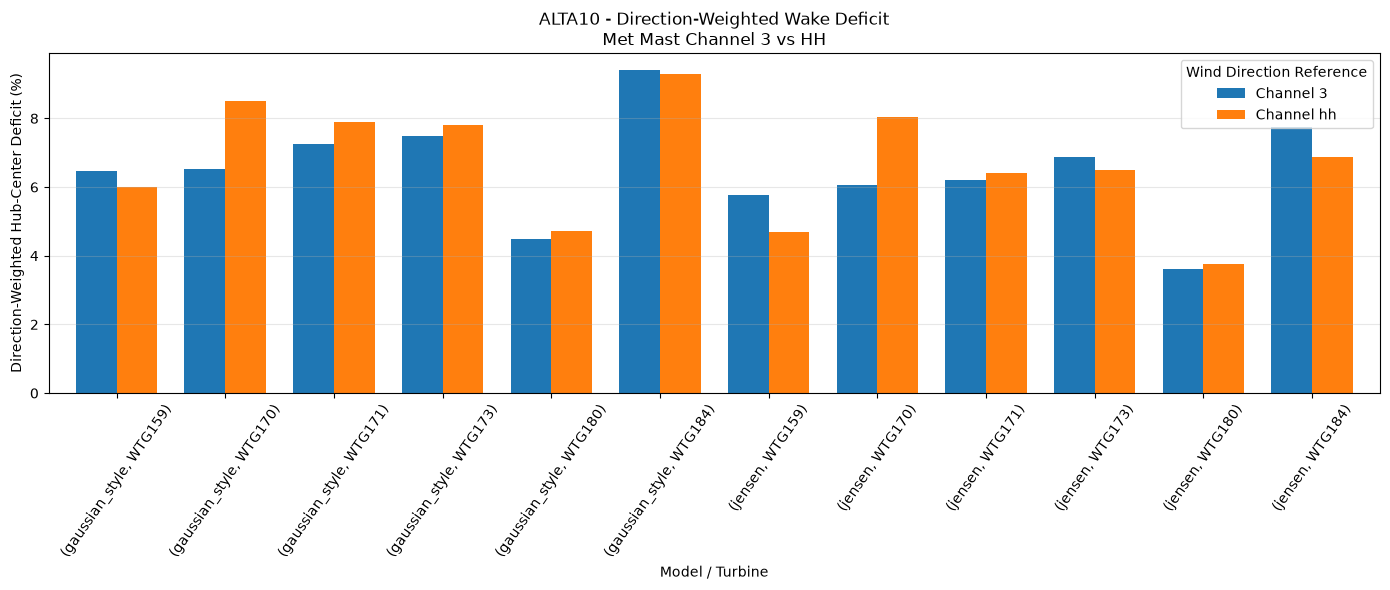

In [23]:
# =====================================================
# ALTA10 - WIND-FREQUENCY-WEIGHTED WAKE EXPOSURE
# Met Mast Channels 3 and HH
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

wind_directions = np.arange(0, 360, 5)

weighted_results = []

# Use the common valid timestamps from our
# previous met mast comparison
for channel in ["3", "hh"]:

    direction = mast_compare[
        f"mm_wind_direction_{channel}"
    ].dropna()

    # Round to nearest simulated 5-degree direction
    direction_bins = (
        np.floor((direction.to_numpy() + 2.5) / 5)
        .astype(int) % 72
    ) * 5

    # Observed wind-direction probabilities
    frequency = (
        pd.Series(direction_bins)
        .value_counts()
        .reindex(wind_directions, fill_value=0)
    )

    frequency = frequency / frequency.sum()

    weights = pd.DataFrame({
        "wind_from_deg": wind_directions,
        "frequency": frequency.to_numpy()
    })

    # Join observed directional frequencies
    # to our existing model simulations
    combined = directional_wakes.merge(
        weights,
        on="wind_from_deg",
        how="inner",
        validate="many_to_one"
    )

    for (model, turbine), group in combined.groupby(
        ["model", "turbine"]
    ):

        weighted_deficit = (
            group["predicted_deficit_pct"]
            * group["frequency"]
        ).sum()

        # Percentage of observations whose
        # direction corresponds to >10% modeled deficit
        wake_exposure = (
            group.loc[
                group["predicted_deficit_pct"] >= 10,
                "frequency"
            ].sum() * 100
        )

        weighted_results.append({
            "reference": f"Channel {channel}",
            "model": model,
            "turbine": turbine,
            "weighted_deficit_pct": weighted_deficit,
            "directional_exposure_pct": wake_exposure
        })

weighted_wakes = pd.DataFrame(weighted_results)

print("ALTA10 - WEIGHTED WAKE EXPOSURE")

display(weighted_wakes.round(2))

# ----------------------------------------------
# Compare both reference direction channels
# ----------------------------------------------

pivot = weighted_wakes.pivot_table(
    index=["model", "turbine"],
    columns="reference",
    values="weighted_deficit_pct"
)

ax = pivot.plot.bar(
    figsize=(14, 6),
    width=0.75
)

ax.set_title(
    "ALTA10 - Direction-Weighted Wake Deficit\n"
    "Met Mast Channel 3 vs HH"
)

ax.set_xlabel("Model / Turbine")
ax.set_ylabel(
    "Direction-Weighted Hub-Center Deficit (%)"
)

ax.tick_params(axis="x", rotation=55)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Wind Direction Reference")

plt.tight_layout()
plt.show()

MATCHED OBSERVATIONS: 24134


,turbine,wake_class,observations,mean_TI,median_TI
0,WTG159,Modeled wake <10%,3839,12.94,12.39
1,WTG159,Modeled wake >=10%,245,24.03,24.49
2,WTG170,Modeled wake <10%,3582,13.96,12.99
3,WTG170,Modeled wake >=10%,459,20.30,20.35
4,WTG171,Modeled wake <10%,3708,14.74,14.12
5,WTG171,Modeled wake >=10%,435,21.91,21.76
6,WTG173,Modeled wake <10%,3617,15.15,15.66
7,WTG173,Modeled wake >=10%,185,21.30,21.19
8,WTG180,Modeled wake <10%,3755,12.15,11.19
9,WTG180,Modeled wake >=10%,279,20.97,20.88


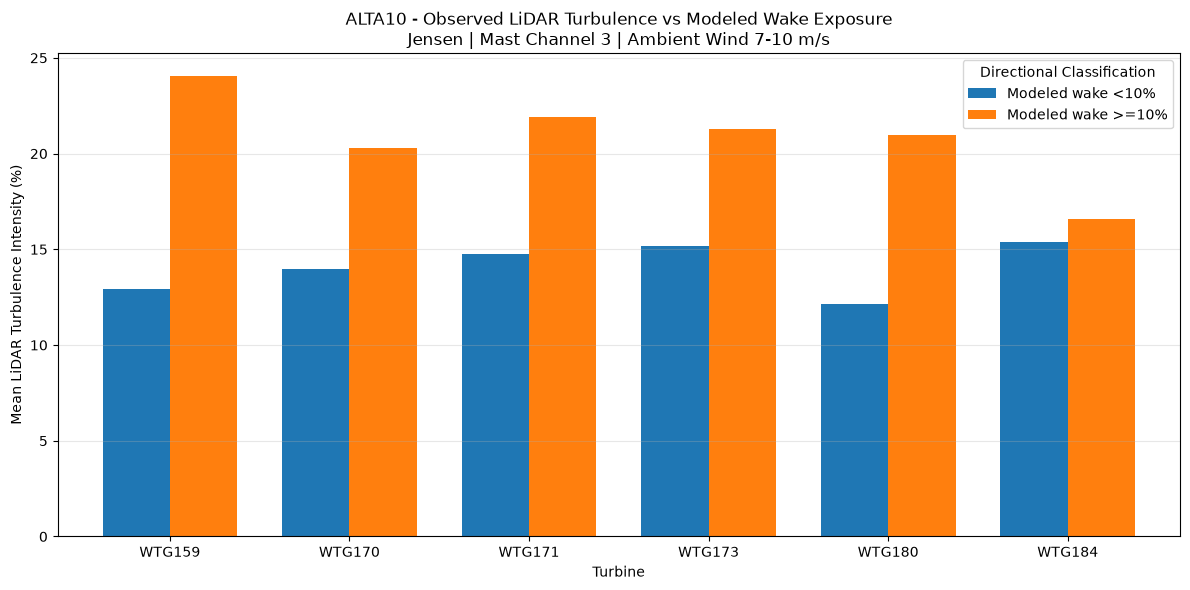

In [24]:
# =====================================================
# ALTA10 - OBSERVED TI VS MODELED WAKE EXPOSURE
# Step 1: Jensen + Met Mast Channel 3
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Initial comparison settings
model = "jensen"
mast_channel = "3"
wake_threshold = 10.0

# 1. Prepare met mast observations
mast = metmasts[
    [
        "utc",
        f"mm_wind_speed_{mast_channel}",
        f"mm_wind_direction_{mast_channel}"
    ]
].copy()

mast.columns = [
    "utc",
    "mast_speed",
    "mast_direction"
]

mast["timestamp"] = pd.to_datetime(
    mast["utc"], errors="coerce", utc=True
).dt.tz_localize(None)

mast["mast_speed"] = pd.to_numeric(
    mast["mast_speed"], errors="coerce"
)

mast["mast_direction"] = pd.to_numeric(
    mast["mast_direction"], errors="coerce"
)

# Limit ambient wind speeds near our 8.2 m/s model
mast = mast[
    mast["mast_speed"].between(7, 10) &
    mast["mast_direction"].between(
        0, 360, inclusive="left"
    )
].copy()

if mast["timestamp"].duplicated().any():
    raise ValueError("Duplicate met mast timestamps.")

# 2. Convert directions to nearest simulated 5 degrees
mast["wind_from_deg"] = (
    np.floor(
        (mast["mast_direction"] + 2.5) / 5
    ).astype(int) * 5
) % 360

# 3. Prepare our LiDAR TI measurements
lidar = valid_lidar[
    ["timestamp", "turbine", "TI", "flagged_interval"]
].copy()

# Exclude preliminary quality-flagged intervals
lidar = lidar[~lidar["flagged_interval"].fillna(False)]

lidar["timestamp"] = pd.to_datetime(
    lidar["timestamp"], errors="coerce", utc=True
).dt.tz_localize(None)

# 4. Match LiDAR TI to met mast observations
matched = lidar.merge(
    mast[["timestamp", "mast_speed", "wind_from_deg"]],
    on="timestamp",
    how="inner",
    validate="many_to_one"
)

# 5. Join the modeled wake deficit for each turbine/direction
wake_lookup = directional_wakes[
    directional_wakes["model"] == model
][
    ["turbine", "wind_from_deg", "predicted_deficit_pct"]
].copy()

matched = matched.merge(
    wake_lookup,
    on=["turbine", "wind_from_deg"],
    how="inner",
    validate="many_to_one"
)

if matched.empty:
    raise ValueError(
        "No matching observations. Verify timestamps "
        "and measurement intervals."
    )

# 6. Classify modeled wake exposure
matched["wake_class"] = np.where(
    matched["predicted_deficit_pct"] >= wake_threshold,
    "Modeled wake >=10%",
    "Modeled wake <10%"
)

matched["TI_pct"] = matched["TI"] * 100

# 7. Compare observed turbulence
ti_wake_results = (
    matched.groupby(
        ["turbine", "wake_class"]
    )
    .agg(
        observations=("TI_pct", "size"),
        mean_TI=("TI_pct", "mean"),
        median_TI=("TI_pct", "median")
    )
    .reset_index()
)

print("MATCHED OBSERVATIONS:", len(matched))
display(ti_wake_results.round(2))

# 8. Visualize mean measured TI by wake classification
plot_data = ti_wake_results.pivot(
    index="turbine",
    columns="wake_class",
    values="mean_TI"
)

ax = plot_data.plot.bar(
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "ALTA10 - Observed LiDAR Turbulence vs Modeled Wake Exposure\n"
    "Jensen | Mast Channel 3 | Ambient Wind 7-10 m/s"
)

ax.set_xlabel("Turbine")
ax.set_ylabel("Mean LiDAR Turbulence Intensity (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Directional Classification")

plt.tight_layout()
plt.show()

ALTA10 - TURBULENCE COMPONENT ANALYSIS


,turbine,wake_class,observations,unique_days,mean_lidar_speed,mean_std_speed,mean_TI_pct
0,WTG159,Modeled wake <10%,3839,128,7.59,0.95,12.94
1,WTG159,Modeled wake >=10%,245,40,5.44,1.28,24.03
2,WTG170,Modeled wake <10%,3582,127,7.38,1.00,13.96
3,WTG170,Modeled wake >=10%,459,57,6.04,1.21,20.30
4,WTG171,Modeled wake <10%,3708,127,7.24,1.05,14.74
5,WTG171,Modeled wake >=10%,435,45,5.81,1.25,21.91
6,WTG173,Modeled wake <10%,3617,127,7.19,1.09,15.15
7,WTG173,Modeled wake >=10%,185,37,5.90,1.24,21.30
8,WTG180,Modeled wake <10%,3755,126,8.65,1.01,12.15
9,WTG180,Modeled wake >=10%,279,41,6.14,1.27,20.97


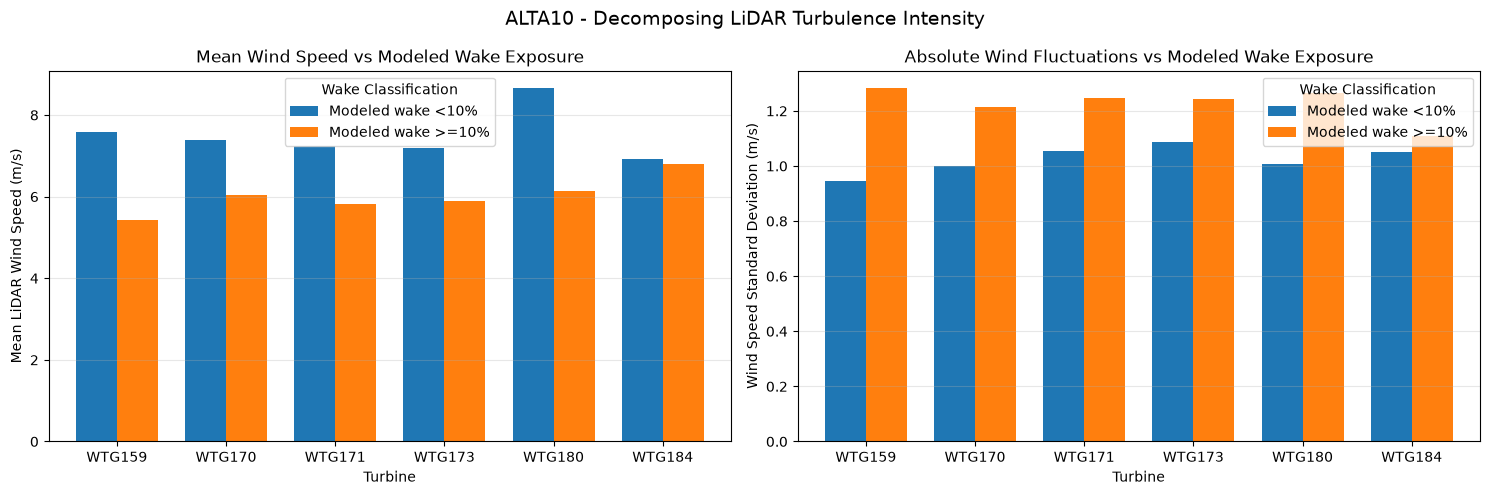

In [25]:
# ======================================================
# ALTA10 - WHY DOES TI INCREASE DURING MODELED WAKES?
# Compare LiDAR mean speed and standard deviation
# ======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Recover original 10-minute LiDAR statistics
lidar_components = valid_lidar[
    ["timestamp", "turbine", "mean_speed", "std_speed"]
].copy()

lidar_components["timestamp"] = pd.to_datetime(
    lidar_components["timestamp"],
    utc=True
).dt.tz_localize(None)

# Use the same observations as our previous wake/TI analysis
ti_components = matched.copy()

ti_components["timestamp"] = pd.to_datetime(
    ti_components["timestamp"],
    utc=True
).dt.tz_localize(None)

ti_components = ti_components.merge(
    lidar_components,
    on=["timestamp", "turbine"],
    how="left",
    validate="one_to_one"
)

ti_components["date"] = (
    ti_components["timestamp"].dt.date
)

# Summarize the two parts of turbulence intensity
component_summary = (
    ti_components.groupby(
        ["turbine", "wake_class"]
    )
    .agg(
        observations=("TI_pct", "size"),
        unique_days=("date", "nunique"),
        mean_lidar_speed=("mean_speed", "mean"),
        mean_std_speed=("std_speed", "mean"),
        mean_TI_pct=("TI_pct", "mean")
    )
    .reset_index()
)

print("ALTA10 - TURBULENCE COMPONENT ANALYSIS")
display(component_summary.round(2))

# ------------------------------------------------------
# Visualize the two components separately
# ------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

plot_settings = [
    (
        "mean_lidar_speed",
        "Mean LiDAR Wind Speed (m/s)",
        "Mean Wind Speed vs Modeled Wake Exposure"
    ),
    (
        "mean_std_speed",
        "Wind Speed Standard Deviation (m/s)",
        "Absolute Wind Fluctuations vs Modeled Wake Exposure"
    )
]

for ax, (column, ylabel, title) in zip(
    axes, plot_settings
):

    plot_data = component_summary.pivot(
        index="turbine",
        columns="wake_class",
        values=column
    )

    plot_data.plot.bar(
        ax=ax,
        width=0.75,
        rot=0
    )

    ax.set_title(title)
    ax.set_xlabel("Turbine")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Wake Classification")

plt.suptitle(
    "ALTA10 - Decomposing LiDAR Turbulence Intensity",
    fontsize=14
)

plt.tight_layout()
plt.show()

ALTA10 - NORMALIZED WIND SPEED ANALYSIS


,turbine,wake_class,observations,mean_mast_speed,mean_lidar_speed,mean_speed_ratio,median_speed_ratio,mean_fluctuation_ratio
0,WTG159,Modeled wake <10%,3839,8.626,7.592,0.877,0.849,0.111
1,WTG159,Modeled wake >=10%,245,8.202,5.437,0.664,0.658,0.156
2,WTG170,Modeled wake <10%,3582,8.628,7.378,0.855,0.846,0.116
3,WTG170,Modeled wake >=10%,459,8.230,6.035,0.731,0.716,0.147
4,WTG171,Modeled wake <10%,3708,8.646,7.244,0.838,0.834,0.122
5,WTG171,Modeled wake >=10%,435,8.284,5.814,0.701,0.686,0.150
6,WTG173,Modeled wake <10%,3617,8.631,7.191,0.833,0.820,0.126
7,WTG173,Modeled wake >=10%,185,8.065,5.905,0.732,0.712,0.154
8,WTG180,Modeled wake <10%,3755,8.641,8.651,1.000,0.980,0.117
9,WTG180,Modeled wake >=10%,279,8.165,6.136,0.754,0.742,0.155


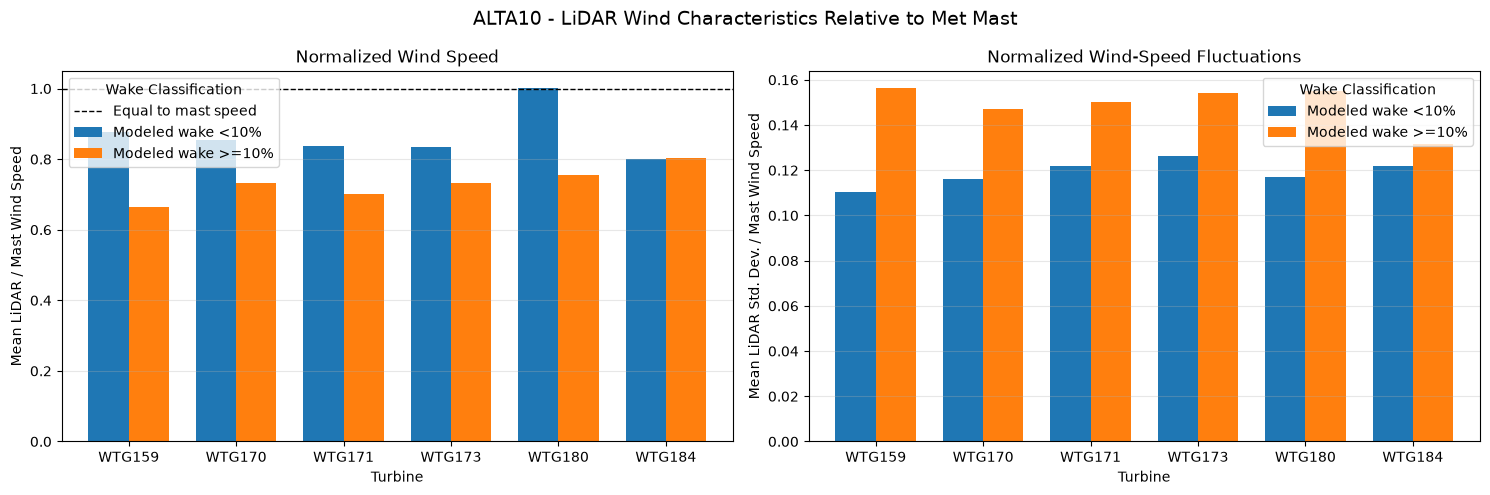

In [26]:
# ======================================================
# ALTA10 - NORMALIZED WIND SPEED AND TURBULENCE
# Compare LiDAR measurements relative to met mast
# ======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

normalized = ti_components.copy()

# Keep matched observations with valid wind speeds
normalized = normalized[
    normalized["mast_speed"].between(7, 10) &
    normalized["mean_speed"].between(0.1, 35) &
    normalized["std_speed"].notna()
].copy()

# ----------------------------------------------
# 1. NORMALIZE AGAINST MET MAST
# ----------------------------------------------

normalized["speed_ratio"] = (
    normalized["mean_speed"] /
    normalized["mast_speed"]
)

normalized["fluctuation_ratio"] = (
    normalized["std_speed"] /
    normalized["mast_speed"]
)

# ----------------------------------------------
# 2. SUMMARIZE BY TURBINE AND WAKE CLASS
# ----------------------------------------------

normalized_summary = (
    normalized.groupby(["turbine", "wake_class"])
    .agg(
        observations=("speed_ratio", "size"),
        mean_mast_speed=("mast_speed", "mean"),
        mean_lidar_speed=("mean_speed", "mean"),
        mean_speed_ratio=("speed_ratio", "mean"),
        median_speed_ratio=("speed_ratio", "median"),
        mean_fluctuation_ratio=("fluctuation_ratio", "mean")
    )
    .reset_index()
)

print("ALTA10 - NORMALIZED WIND SPEED ANALYSIS")
display(normalized_summary.round(3))

# ----------------------------------------------
# 3. VISUALIZE THE NORMALIZED RESULTS
# ----------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

metrics = [
    (
        "mean_speed_ratio",
        "Mean LiDAR / Mast Wind Speed",
        "Normalized Wind Speed"
    ),
    (
        "mean_fluctuation_ratio",
        "Mean LiDAR Std. Dev. / Mast Wind Speed",
        "Normalized Wind-Speed Fluctuations"
    )
]

for ax, (column, ylabel, title) in zip(
    axes, metrics
):

    plot_data = normalized_summary.pivot(
        index="turbine",
        columns="wake_class",
        values=column
    )

    plot_data.plot.bar(
        ax=ax,
        width=0.75,
        rot=0
    )

    if column == "mean_speed_ratio":
        ax.axhline(
            1,
            color="black",
            linestyle="--",
            linewidth=1,
            label="Equal to mast speed"
        )

    ax.set_title(title)
    ax.set_xlabel("Turbine")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Wake Classification")

plt.suptitle(
    "ALTA10 - LiDAR Wind Characteristics Relative to Met Mast",
    fontsize=14
)

plt.tight_layout()
plt.show()

Common matched observations: 17638

FOUR-WAY MODEL COMPARISON


,turbine,model,mast_channel,low_n,wake_n,speed_ratio_change,fluctuation_ratio_change
0,WTG159,jensen,3,2766,187,-0.233,0.044
1,WTG170,jensen,3,2625,339,-0.129,0.030
2,WTG171,jensen,3,2663,346,-0.140,0.029
3,WTG173,jensen,3,2583,132,-0.084,0.027
4,WTG180,jensen,3,2737,215,-0.266,0.039
5,WTG184,jensen,3,1998,1047,0.008,0.011
6,WTG159,gaussian_style,3,2662,291,-0.189,0.045
7,WTG170,gaussian_style,3,2453,511,-0.131,0.034
8,WTG171,gaussian_style,3,2624,385,-0.129,0.031
9,WTG173,gaussian_style,3,2541,174,-0.074,0.029


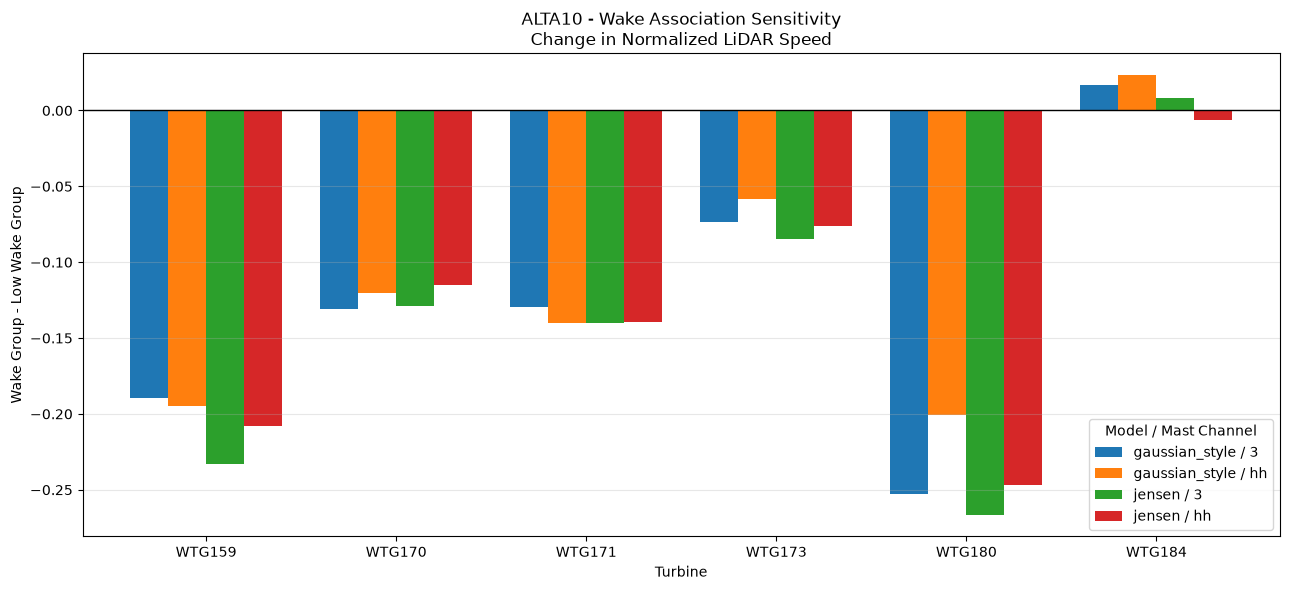

In [27]:
# =====================================================
# ALTA10 - WAKE / LIDAR ROBUSTNESS COMPARISON
# Jensen vs Gaussian | Mast Channel 3 vs HH
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

models = ["jensen", "gaussian_style"]
channels = ["3", "hh"]

# -----------------------------------------------------
# 1. PREPARE COMMON MET MAST OBSERVATIONS
# -----------------------------------------------------

mast_data = metmasts[
    [
        "utc",
        "mm_wind_speed_3",
        "mm_wind_direction_3",
        "mm_wind_speed_hh",
        "mm_wind_direction_hh"
    ]
].copy()

mast_data["timestamp"] = pd.to_datetime(
    mast_data["utc"], errors="coerce", utc=True
).dt.tz_localize(None)

for col in mast_data.columns:
    if col not in ["utc", "timestamp"]:
        mast_data[col] = pd.to_numeric(
            mast_data[col], errors="coerce"
        )

# Select observations valid for BOTH channels
valid = pd.Series(True, index=mast_data.index)

for ch in channels:
    valid &= (
        mast_data[f"mm_wind_speed_{ch}"].between(7, 10) &
        mast_data[f"mm_wind_direction_{ch}"].between(
            0, 360, inclusive="left"
        )
    )

mast_data = mast_data.loc[valid].copy()

if mast_data["timestamp"].duplicated().any():
    raise ValueError("Duplicate mast timestamps detected.")

# -----------------------------------------------------
# 2. MATCH TO LIDAR DATA
# -----------------------------------------------------

lidar_data = valid_lidar[
    [
        "timestamp", "turbine",
        "mean_speed", "std_speed",
        "flagged_interval"
    ]
].copy()

lidar_data = lidar_data[
    ~lidar_data["flagged_interval"].fillna(False)
].copy()

lidar_data["timestamp"] = pd.to_datetime(
    lidar_data["timestamp"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

common = lidar_data.merge(
    mast_data.drop(columns="utc"),
    on="timestamp",
    how="inner",
    validate="many_to_one"
)

common = common[
    common["mean_speed"].between(0.1, 35) &
    common["std_speed"].notna()
].copy()

print("Common matched observations:", len(common))

# -----------------------------------------------------
# 3. EVALUATE ALL FOUR CONFIGURATIONS
# -----------------------------------------------------

results = []

for channel in channels:

    data = common.copy()

    mast_speed = data[f"mm_wind_speed_{channel}"]
    mast_direction = data[f"mm_wind_direction_{channel}"]

    data["speed_ratio"] = (
        data["mean_speed"] / mast_speed
    )

    data["fluctuation_ratio"] = (
        data["std_speed"] / mast_speed
    )

    data["wind_from_deg"] = (
        np.floor(
            (mast_direction + 2.5) / 5
        ).astype(int) * 5
    ) % 360

    for model in models:

        wake_lookup = directional_wakes[
            directional_wakes["model"] == model
        ][
            [
                "turbine",
                "wind_from_deg",
                "predicted_deficit_pct"
            ]
        ].copy()

        scenario = data.merge(
            wake_lookup,
            on=["turbine", "wind_from_deg"],
            how="inner",
            validate="many_to_one"
        )

        scenario["wake_class"] = np.where(
            scenario["predicted_deficit_pct"] >= 10,
            "Wake",
            "Low wake"
        )

        for turbine, group in scenario.groupby("turbine"):

            low = group[group["wake_class"] == "Low wake"]
            wake = group[group["wake_class"] == "Wake"]

            if low.empty or wake.empty:
                continue

            results.append({
                "turbine": turbine,
                "model": model,
                "mast_channel": channel,
                "low_n": len(low),
                "wake_n": len(wake),
                "speed_ratio_change":
                    wake["speed_ratio"].mean() -
                    low["speed_ratio"].mean(),
                "fluctuation_ratio_change":
                    wake["fluctuation_ratio"].mean() -
                    low["fluctuation_ratio"].mean()
            })

robustness = pd.DataFrame(results)

print("\nFOUR-WAY MODEL COMPARISON")
display(robustness.round(3))

# -----------------------------------------------------
# 4. PLOT NORMALIZED SPEED CHANGES
# -----------------------------------------------------

robustness["scenario"] = (
    robustness["model"] + " / " +
    robustness["mast_channel"]
)

plot_data = robustness.pivot(
    index="turbine",
    columns="scenario",
    values="speed_ratio_change"
).reindex(LIDAR_TURBINES)

ax = plot_data.plot.bar(
    figsize=(13, 6),
    width=0.8
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "ALTA10 - Wake Association Sensitivity\n"
    "Change in Normalized LiDAR Speed"
)

ax.set_xlabel("Turbine")
ax.set_ylabel("Wake Group - Low Wake Group")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model / Mast Channel")

plt.tight_layout()
plt.show()

ALTA10 - WIND DIRECTION SENSITIVITY


,turbine,scenarios,minimum_change,maximum_change,negative_scenarios,min_wake_observations
0,WTG159,20,-0.247,-0.115,20,119
1,WTG170,20,-0.135,0.023,18,249
2,WTG171,20,-0.164,-0.042,20,219
3,WTG173,20,-0.112,-0.004,20,83
4,WTG180,20,-0.270,-0.187,20,175
5,WTG184,20,-0.006,0.036,2,548


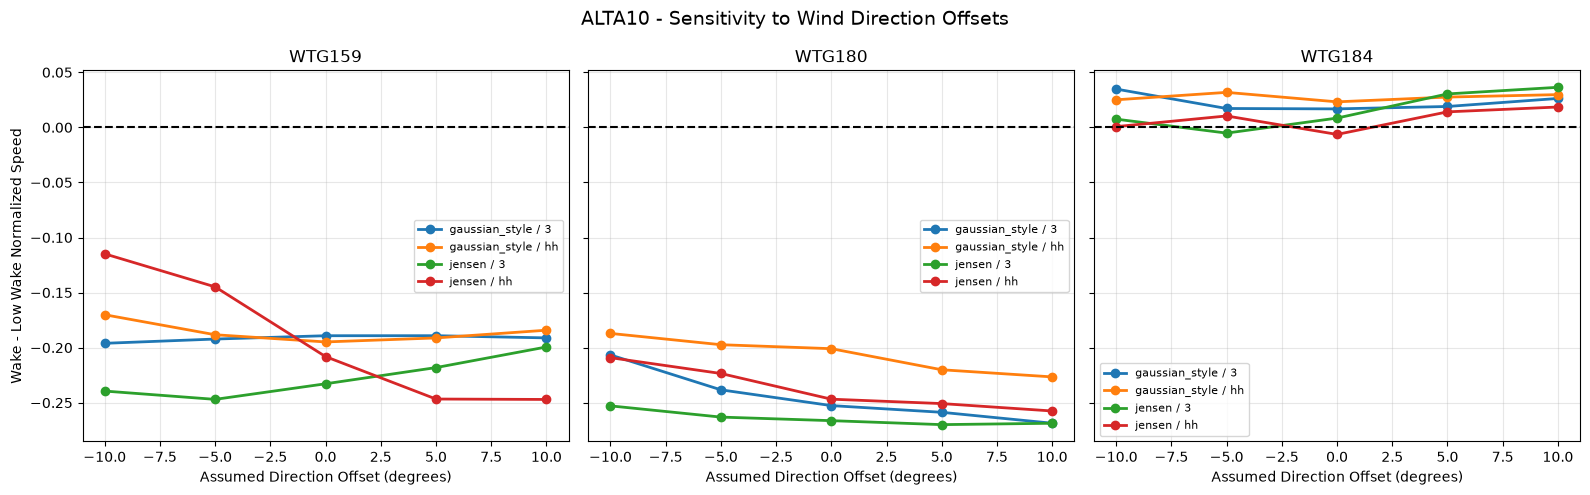

In [28]:
# ======================================================
# ALTA10 - WIND DIRECTION UNCERTAINTY TEST
# Testing hypothetical mast direction offsets
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

offsets = [-10, -5, 0, 5, 10]
models = ["jensen", "gaussian_style"]
channels = ["3", "hh"]

results = []

for channel in channels:

    base = common.copy()

    base["speed_ratio"] = (
        base["mean_speed"] /
        base[f"mm_wind_speed_{channel}"]
    )

    original_dir = base[
        f"mm_wind_direction_{channel}"
    ]

    for offset in offsets:

        data = base.copy()

        adjusted_dir = (original_dir + offset) % 360

        data["wind_from_deg"] = (
            np.floor((adjusted_dir + 2.5) / 5)
            .astype(int) * 5
        ) % 360

        for model in models:

            lookup = directional_wakes[
                directional_wakes["model"] == model
            ][[
                "turbine",
                "wind_from_deg",
                "predicted_deficit_pct"
            ]]

            comparison = data.merge(
                lookup,
                on=["turbine", "wind_from_deg"],
                how="inner",
                validate="many_to_one"
            )

            comparison["wake_exposed"] = (
                comparison["predicted_deficit_pct"] >= 10
            )

            for turbine, group in comparison.groupby(
                "turbine"
            ):

                low = group.loc[
                    ~group["wake_exposed"], "speed_ratio"
                ].dropna()

                high = group.loc[
                    group["wake_exposed"], "speed_ratio"
                ].dropna()

                if len(low) < 30 or len(high) < 30:
                    continue

                results.append({
                    "turbine": turbine,
                    "model": model,
                    "channel": channel,
                    "offset_deg": offset,
                    "low_n": len(low),
                    "wake_n": len(high),
                    "speed_ratio_change":
                        high.mean() - low.mean()
                })

angle_sensitivity = pd.DataFrame(results)

# ----------------------------------------------
# Summarize sensitivity across all configurations
# ----------------------------------------------

angle_summary = (
    angle_sensitivity.groupby("turbine")
    .agg(
        scenarios=("speed_ratio_change", "size"),
        minimum_change=("speed_ratio_change", "min"),
        maximum_change=("speed_ratio_change", "max"),
        negative_scenarios=(
            "speed_ratio_change",
            lambda x: (x < 0).sum()
        ),
        min_wake_observations=("wake_n", "min")
    )
    .reset_index()
)

print("ALTA10 - WIND DIRECTION SENSITIVITY")
display(angle_summary.round(3))

# ----------------------------------------------
# Examine three turbines in detail
# ----------------------------------------------

selected_turbines = [
    "WTG159",
    "WTG180",
    "WTG184"
]

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5),
    sharey=True
)

for ax, turbine in zip(
    axes, selected_turbines
):

    subset = angle_sensitivity[
        angle_sensitivity["turbine"] == turbine
    ]

    for (model, channel), group in subset.groupby(
        ["model", "channel"]
    ):

        group = group.sort_values("offset_deg")

        ax.plot(
            group["offset_deg"],
            group["speed_ratio_change"],
            marker="o",
            linewidth=2,
            label=f"{model} / {channel}"
        )

    ax.axhline(
        0, color="black", linestyle="--"
    )

    ax.set_title(turbine)
    ax.set_xlabel("Assumed Direction Offset (degrees)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel(
    "Wake - Low Wake Normalized Speed"
)

plt.suptitle(
    "ALTA10 - Sensitivity to Wind Direction Offsets",
    fontsize=14
)

plt.tight_layout()
plt.show()

ALTA10 - DAY-LEVEL BOOTSTRAP RESULTS


,turbine,total_days,wake_days,low_wake_days,wake_observations,low_wake_observations,observed_change,CI_lower,CI_upper
0,WTG159,124,35,124,187,2766,-0.233,-0.265,-0.195
1,WTG170,121,49,121,339,2625,-0.129,-0.163,-0.094
2,WTG171,122,38,121,346,2663,-0.140,-0.190,-0.090
3,WTG173,123,29,123,132,2583,-0.084,-0.126,-0.027
4,WTG180,122,37,122,215,2737,-0.266,-0.326,-0.208
5,WTG184,124,109,122,1047,1998,0.008,-0.009,0.025


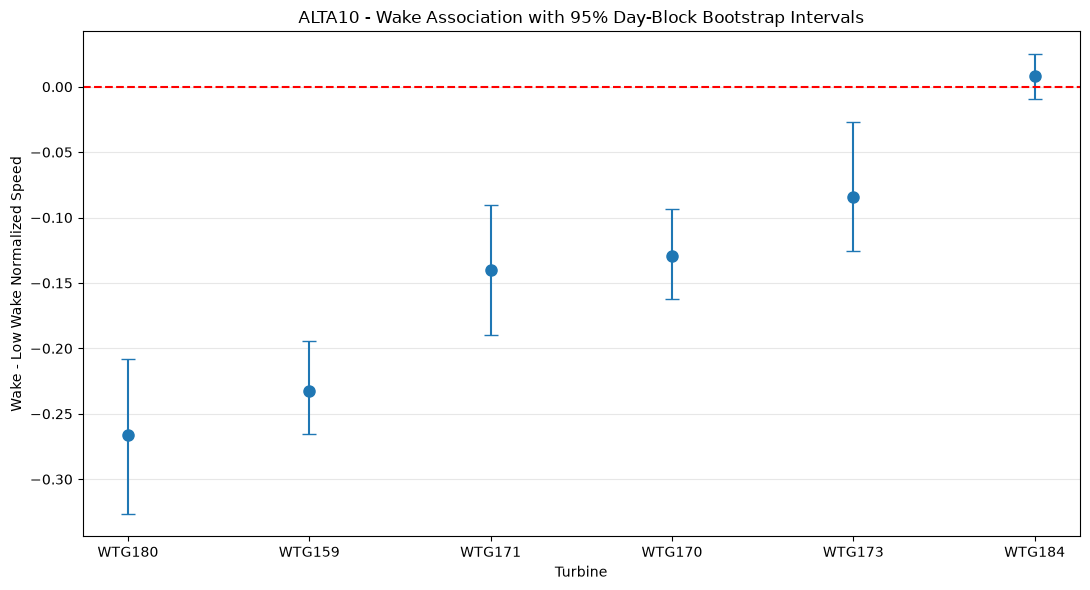

In [29]:
# =====================================================
# ALTA10 - DAY-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
# Jensen Model | Met Mast Channel 3
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n_bootstrap = 1500

# ---------------------------------------------
# 1. REBUILD THE BASELINE COMPARISON
# ---------------------------------------------

data = common.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

data["date"] = data["timestamp"].dt.floor("D")

data["speed_ratio"] = (
    data["mean_speed"] /
    data["mm_wind_speed_3"]
)

data["wind_from_deg"] = (
    np.floor(
        (data["mm_wind_direction_3"] + 2.5) / 5
    ).astype(int) * 5
) % 360

lookup = directional_wakes[
    directional_wakes["model"] == "jensen"
][[
    "turbine",
    "wind_from_deg",
    "predicted_deficit_pct"
]]

data = data.merge(
    lookup,
    on=["turbine", "wind_from_deg"],
    how="inner",
    validate="many_to_one"
)

data["wake_exposed"] = (
    data["predicted_deficit_pct"] >= 10
)

# ---------------------------------------------
# 2. BOOTSTRAP COMPLETE DAYS
# ---------------------------------------------

results = []

for turbine, group in data.groupby("turbine"):

    # Sum and count measurements for each day
    # in both modeled exposure classes

    daily_sum = (
        group.groupby(["date", "wake_exposed"])
        ["speed_ratio"]
        .sum()
        .unstack(fill_value=0)
        .reindex(columns=[False, True], fill_value=0)
    )

    daily_count = (
        group.groupby(["date", "wake_exposed"])
        ["speed_ratio"]
        .count()
        .unstack(fill_value=0)
        .reindex(columns=[False, True], fill_value=0)
    )

    sums = daily_sum.to_numpy(dtype=float)
    counts = daily_count.to_numpy(dtype=float)

    n_days = len(sums)

    if counts.sum(axis=0).min() == 0:
        continue

    # Observed wake minus low-wake difference
    observed_means = (
        sums.sum(axis=0) / counts.sum(axis=0)
    )

    observed_change = (
        observed_means[1] - observed_means[0]
    )

    # Resample entire days with replacement
    indices = rng.integers(
        0, n_days,
        size=(n_bootstrap, n_days)
    )

    bootstrap_sums = sums[indices].sum(axis=1)
    bootstrap_counts = counts[indices].sum(axis=1)

    valid_draws = (
        bootstrap_counts.min(axis=1) > 0
    )

    bootstrap_means = (
        bootstrap_sums[valid_draws] /
        bootstrap_counts[valid_draws]
    )

    bootstrap_changes = (
        bootstrap_means[:, 1] -
        bootstrap_means[:, 0]
    )

    ci_lower, ci_upper = np.percentile(
        bootstrap_changes,
        [2.5, 97.5]
    )

    results.append({
        "turbine": turbine,
        "total_days": n_days,
        "wake_days": int((counts[:, 1] > 0).sum()),
        "low_wake_days": int((counts[:, 0] > 0).sum()),
        "wake_observations": int(counts[:, 1].sum()),
        "low_wake_observations": int(counts[:, 0].sum()),
        "observed_change": observed_change,
        "CI_lower": ci_lower,
        "CI_upper": ci_upper
    })

bootstrap_results = pd.DataFrame(results)

print("ALTA10 - DAY-LEVEL BOOTSTRAP RESULTS")
display(bootstrap_results.round(3))

# ---------------------------------------------
# 3. PLOT CONFIDENCE INTERVALS
# ---------------------------------------------

plot_data = bootstrap_results.sort_values(
    "observed_change"
)

x = np.arange(len(plot_data))

lower_error = (
    plot_data["observed_change"] -
    plot_data["CI_lower"]
)

upper_error = (
    plot_data["CI_upper"] -
    plot_data["observed_change"]
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.errorbar(
    x,
    plot_data["observed_change"],
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=5,
    markersize=8
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data["turbine"])

ax.set_xlabel("Turbine")
ax.set_ylabel(
    "Wake - Low Wake Normalized Speed"
)

ax.set_title(
    "ALTA10 - Wake Association with 95% "
    "Day-Block Bootstrap Intervals"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [30]:
# ======================================================
# ALTA10 - MATCHED ENVIRONMENTAL CONDITIONS
# Jensen | Mast Channel 3
# Control for month and ambient wind-speed range
# ======================================================

import numpy as np
import pandas as pd

# Reuse the common valid observations
adjusted = common.copy()

adjusted["timestamp"] = pd.to_datetime(
    adjusted["timestamp"], utc=True
).dt.tz_localize(None)

adjusted["month"] = (
    adjusted["timestamp"].dt.to_period("M")
)

# 0.5 m/s ambient wind-speed categories
adjusted["mast_speed_bin"] = pd.cut(
    adjusted["mm_wind_speed_3"],
    bins=np.arange(7, 10.51, 0.5),
    right=False
)

# Calculate normalized LiDAR wind speed
adjusted["speed_ratio"] = (
    adjusted["mean_speed"] /
    adjusted["mm_wind_speed_3"]
)

# Match wind direction to our simulated angles
adjusted["wind_from_deg"] = (
    np.floor(
        (adjusted["mm_wind_direction_3"] + 2.5) / 5
    ).astype(int) * 5
) % 360

# Jensen predicted wake deficits
wake_lookup = directional_wakes[
    directional_wakes["model"] == "jensen"
][
    ["turbine", "wind_from_deg", "predicted_deficit_pct"]
].copy()

adjusted = adjusted.merge(
    wake_lookup,
    on=["turbine", "wind_from_deg"],
    how="inner",
    validate="many_to_one"
)

adjusted["wake_exposed"] = (
    adjusted["predicted_deficit_pct"] >= 10
)

# ------------------------------------------------------
# 1. Calculate group means within matched conditions
# ------------------------------------------------------

strata = ["turbine", "month", "mast_speed_bin"]

summaries = (
    adjusted.groupby(
        strata + ["wake_exposed"],
        observed=True
    )
    .agg(
        mean_ratio=("speed_ratio", "mean"),
        observations=("speed_ratio", "count")
    )
    .reset_index()
)

low = summaries[
    ~summaries["wake_exposed"]
].rename(columns={
    "mean_ratio": "low_mean",
    "observations": "low_n"
})

high = summaries[
    summaries["wake_exposed"]
].rename(columns={
    "mean_ratio": "wake_mean",
    "observations": "wake_n"
})

# Keep only month/speed combinations with both groups
matched_strata = low.merge(
    high,
    on=strata,
    how="inner"
)

# Require at least 5 observations in each group
matched_strata = matched_strata[
    (matched_strata["low_n"] >= 5) &
    (matched_strata["wake_n"] >= 5)
].copy()

matched_strata["ratio_difference"] = (
    matched_strata["wake_mean"] -
    matched_strata["low_mean"]
)

# ------------------------------------------------------
# 2. Compare adjusted vs original differences
# ------------------------------------------------------

results = []

for turbine, group in adjusted.groupby("turbine"):

    subset = matched_strata[
        matched_strata["turbine"] == turbine
    ]

    wake = group[group["wake_exposed"]]
    low_wake = group[~group["wake_exposed"]]

    original_difference = (
        wake["speed_ratio"].mean() -
        low_wake["speed_ratio"].mean()
    )

    if subset.empty:
        adjusted_difference = np.nan
        retained_wake = 0
    else:
        # Weight each matched stratum by its
        # number of wake-exposed observations
        adjusted_difference = np.average(
            subset["ratio_difference"],
            weights=subset["wake_n"]
        )

        retained_wake = subset["wake_n"].sum()

    results.append({
        "turbine": turbine,
        "original_change": original_difference,
        "adjusted_change": adjusted_difference,
        "matched_strata": len(subset),
        "wake_obs_matched": int(retained_wake),
        "wake_coverage_pct":
            100 * retained_wake / len(wake)
            if len(wake) else np.nan
    })

adjusted_results = pd.DataFrame(results)

print("ALTA10 - MONTH AND WIND-SPEED ADJUSTMENT")
display(adjusted_results.round(3))

ALTA10 - MONTH AND WIND-SPEED ADJUSTMENT


,turbine,original_change,adjusted_change,matched_strata,wake_obs_matched,wake_coverage_pct
0,WTG159,-0.233,-0.240,18,154,82.353
1,WTG170,-0.129,-0.134,25,329,97.050
2,WTG171,-0.140,-0.139,25,334,96.532
3,WTG173,-0.084,-0.102,12,101,76.515
4,WTG180,-0.266,-0.275,20,192,89.302
5,WTG184,0.008,0.005,30,1047,100.000


ALTA10 - SAME-TIME WAKE COMPARISON
---------------------------------------------
Matched 10-minute timestamps: 886
Unique days: 108
Mean relative speed difference: -0.0193
Median relative speed difference: -0.0224
Percent of timestamps with negative difference: 58.69


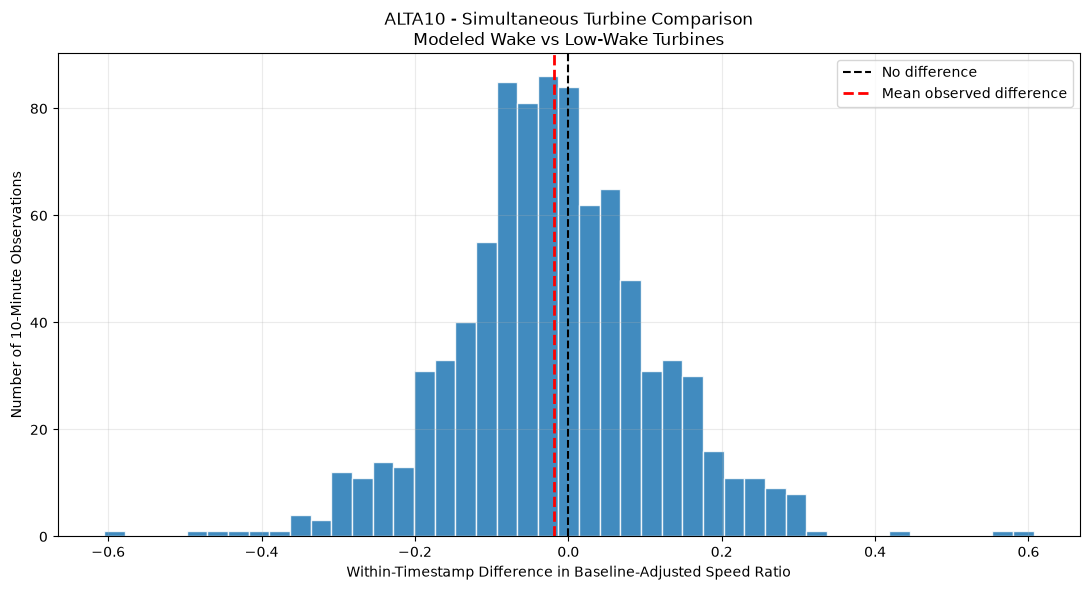

In [31]:
# ======================================================
# ALTA10 - SAME-TIMESTAMP WAKE COMPARISON
# Jensen Model | Met Mast Channel 3
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare matched observations
same_time = common.copy()

same_time["timestamp"] = pd.to_datetime(
    same_time["timestamp"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

same_time["speed_ratio"] = (
    same_time["mean_speed"] /
    same_time["mm_wind_speed_3"]
)

same_time["wind_from_deg"] = (
    np.floor(
        (same_time["mm_wind_direction_3"] + 2.5) / 5
    ).astype(int) * 5
) % 360

# 2. Match the Jensen model predictions
lookup = directional_wakes[
    directional_wakes["model"] == "jensen"
][[
    "turbine",
    "wind_from_deg",
    "predicted_deficit_pct"
]].copy()

same_time = same_time.merge(
    lookup,
    on=["turbine", "wind_from_deg"],
    how="inner",
    validate="many_to_one"
)

same_time["wake_exposed"] = (
    same_time["predicted_deficit_pct"] >= 10
)

# 3. Establish a separate reference level
# for each turbine during low modeled wake exposure
baseline = (
    same_time.loc[~same_time["wake_exposed"]]
    .groupby("turbine")["speed_ratio"]
    .median()
)

same_time["baseline_ratio"] = (
    same_time["turbine"].map(baseline)
)

same_time["relative_speed"] = (
    same_time["speed_ratio"] -
    same_time["baseline_ratio"]
)

# 4. Compare turbine groups at exactly
# the same 10-minute timestamps
simultaneous = (
    same_time.groupby(
        ["timestamp", "wake_exposed"]
    )["relative_speed"]
    .mean()
    .unstack()
    .reindex(columns=[False, True])
)

# Only times when both wake-exposed and
# low-wake turbines have valid data
simultaneous = simultaneous.dropna().copy()

simultaneous.columns = [
    "low_wake_relative_speed",
    "wake_relative_speed"
]

simultaneous["difference"] = (
    simultaneous["wake_relative_speed"] -
    simultaneous["low_wake_relative_speed"]
)

if simultaneous.empty:
    raise ValueError(
        "No timestamps contain both modeled wake "
        "and low-wake turbines."
    )

simultaneous["date"] = (
    simultaneous.index.normalize()
)

# 5. Summarize results
print("ALTA10 - SAME-TIME WAKE COMPARISON")
print("-" * 45)

print(
    "Matched 10-minute timestamps:",
    len(simultaneous)
)

print(
    "Unique days:",
    simultaneous["date"].nunique()
)

print(
    "Mean relative speed difference:",
    round(simultaneous["difference"].mean(), 4)
)

print(
    "Median relative speed difference:",
    round(simultaneous["difference"].median(), 4)
)

print(
    "Percent of timestamps with negative difference:",
    round(
        (simultaneous["difference"] < 0).mean() * 100,
        2
    )
)

# 6. Plot the distribution
fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    simultaneous["difference"],
    bins=45,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="No difference"
)

ax.axvline(
    simultaneous["difference"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mean observed difference"
)

ax.set_title(
    "ALTA10 - Simultaneous Turbine Comparison\n"
    "Modeled Wake vs Low-Wake Turbines"
)

ax.set_xlabel(
    "Within-Timestamp Difference "
    "in Baseline-Adjusted Speed Ratio"
)

ax.set_ylabel(
    "Number of 10-Minute Observations"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()